# Agent 2: nextLevelPersonalCoachForCareerLevel

CMPE 256, SJSU, Fall 2026. **Goal: get ready for my next career step, and measure that I'm getting there.**

The agent finds open internships, jobs, research positions and entrepreneurial programs that match my targets, extracts the skills they ask for, and coaches me on my biggest gaps in an interactive session: it asks concept, coding and scenario questions, grades my answers against a hidden reference (running tests for code), and probes or challenges me with follow-ups. Each session ends with a **Career Readiness Report**: matched opportunities, strengths and gaps with evidence, readiness per skill and per target role, recommended resources, and a 2-week preparation plan. It tracks my progress across sessions and uses what I read through Agent 1 as learning evidence.

This notebook covers all five assignment deliverables for Agent 2:

| # | Deliverable | Section |
|---|---|---|
| 1 | Agent goals: purpose and expected outcomes | [1. Agent goals](#1.-Agent-goals) |
| 2 | Architecture diagram: workflow, tools, data sources, memory | [2. Architecture](#2.-Architecture) |
| 3 | Working prototype | [3. Working prototype](#3.-Working-prototype) |
| 4 | Sample results: an interactive career coaching session | [4. Sample results](#4.-Sample-results) |
| 5 | Evaluation: effectiveness, accuracy, user progress | [5. Evaluation](#5.-Evaluation) |

Full design notes: [ARCHITECTURE.md](ARCHITECTURE.md). To re-run: copy `.env.example` (repo root) to `.env`, fill in the API keys, run a coaching session in a terminal (`python agent.py`, since it asks questions interactively), then run this notebook from this folder with the repo's `.venv` kernel.

## 1. Agent goals

**Purpose.** Turn "I want an ML/AI internship and a path into astrophysics research" into a measured, repeatable preparation loop. I'm an MS Software Engineering student with a BS in Astrophysics, targeting an ML/AI engineer internship (summer 2027), applied AI / LLM agent roles, research assistant positions and PhD programs in ML for astronomy, and, at low priority, AI startup programs and hackathons.

**Expected outcome of each session:** a *Career Readiness Report* (`reports/YYYY-MM-DD.md`) and a transcript of the coaching session (`sessions/YYYY-MM-DD.md`) with:

- **opportunities**: matched postings with organization, type, deadline, fit score and a verified URL taken from the search result (never written by the LLM); closed, expired and ineligible postings are dropped
- **requirements**: the skills those postings ask for, each backed by a quoted line from the posting, ranked by demand
- **assessment**: every question, my answer, the score per rubric criterion, test results for code, written feedback, and a follow-up that probes a weak answer or challenges a strong one
- **strengths and gaps**: each citing the answers or posting requirements that support it
- **readiness**: per skill (from graded answers, falling back to my self-rating and Agent 1 reading) and per target role, with the change since the last session
- **plan**: verified learning resources and a 2-week plan of checkable tasks; unfinished tasks are checked in on and carried over next session

**What success looks like**, and how section 5 measures it:

| Goal | Measured by |
|---|---|
| Effective: real, relevant opportunities and useful practice on my gaps | postings still open and matching my target types; question relevance and difficulty fit (LLM judge); follow-ups that improve on a weak answer |
| Accurate: nothing invented, fair grading | requirement quotes found in the posting text; links resolve; findings cite valid evidence; grader agreement with my hand-labeled answers |
| Progress: I get more ready over time | readiness per skill and per target across sessions; plan tasks completed on time; gaps that become strengths |

## 2. Architecture

The agent is a **LangGraph `StateGraph`** with two human-in-the-loop steps (the plan check-in and the question loop, both `interrupt()`), a conditional discovery branch (search only when stored opportunities are older than 7 days), and a grading loop that adds at most one follow-up per question. As in Agent 1, the LLM is used only where judgment is needed (planning searches, extracting requirements, writing and grading questions, coaching); search, link checks, test runs, scoring math and report metadata are plain code.

### 2.1 Workflow, tools and memory

Rendered from the Mermaid source in [ARCHITECTURE.md](ARCHITECTURE.md). Solid arrows are the graph's control flow; dotted arrows show which nodes call which tools and memory stores.

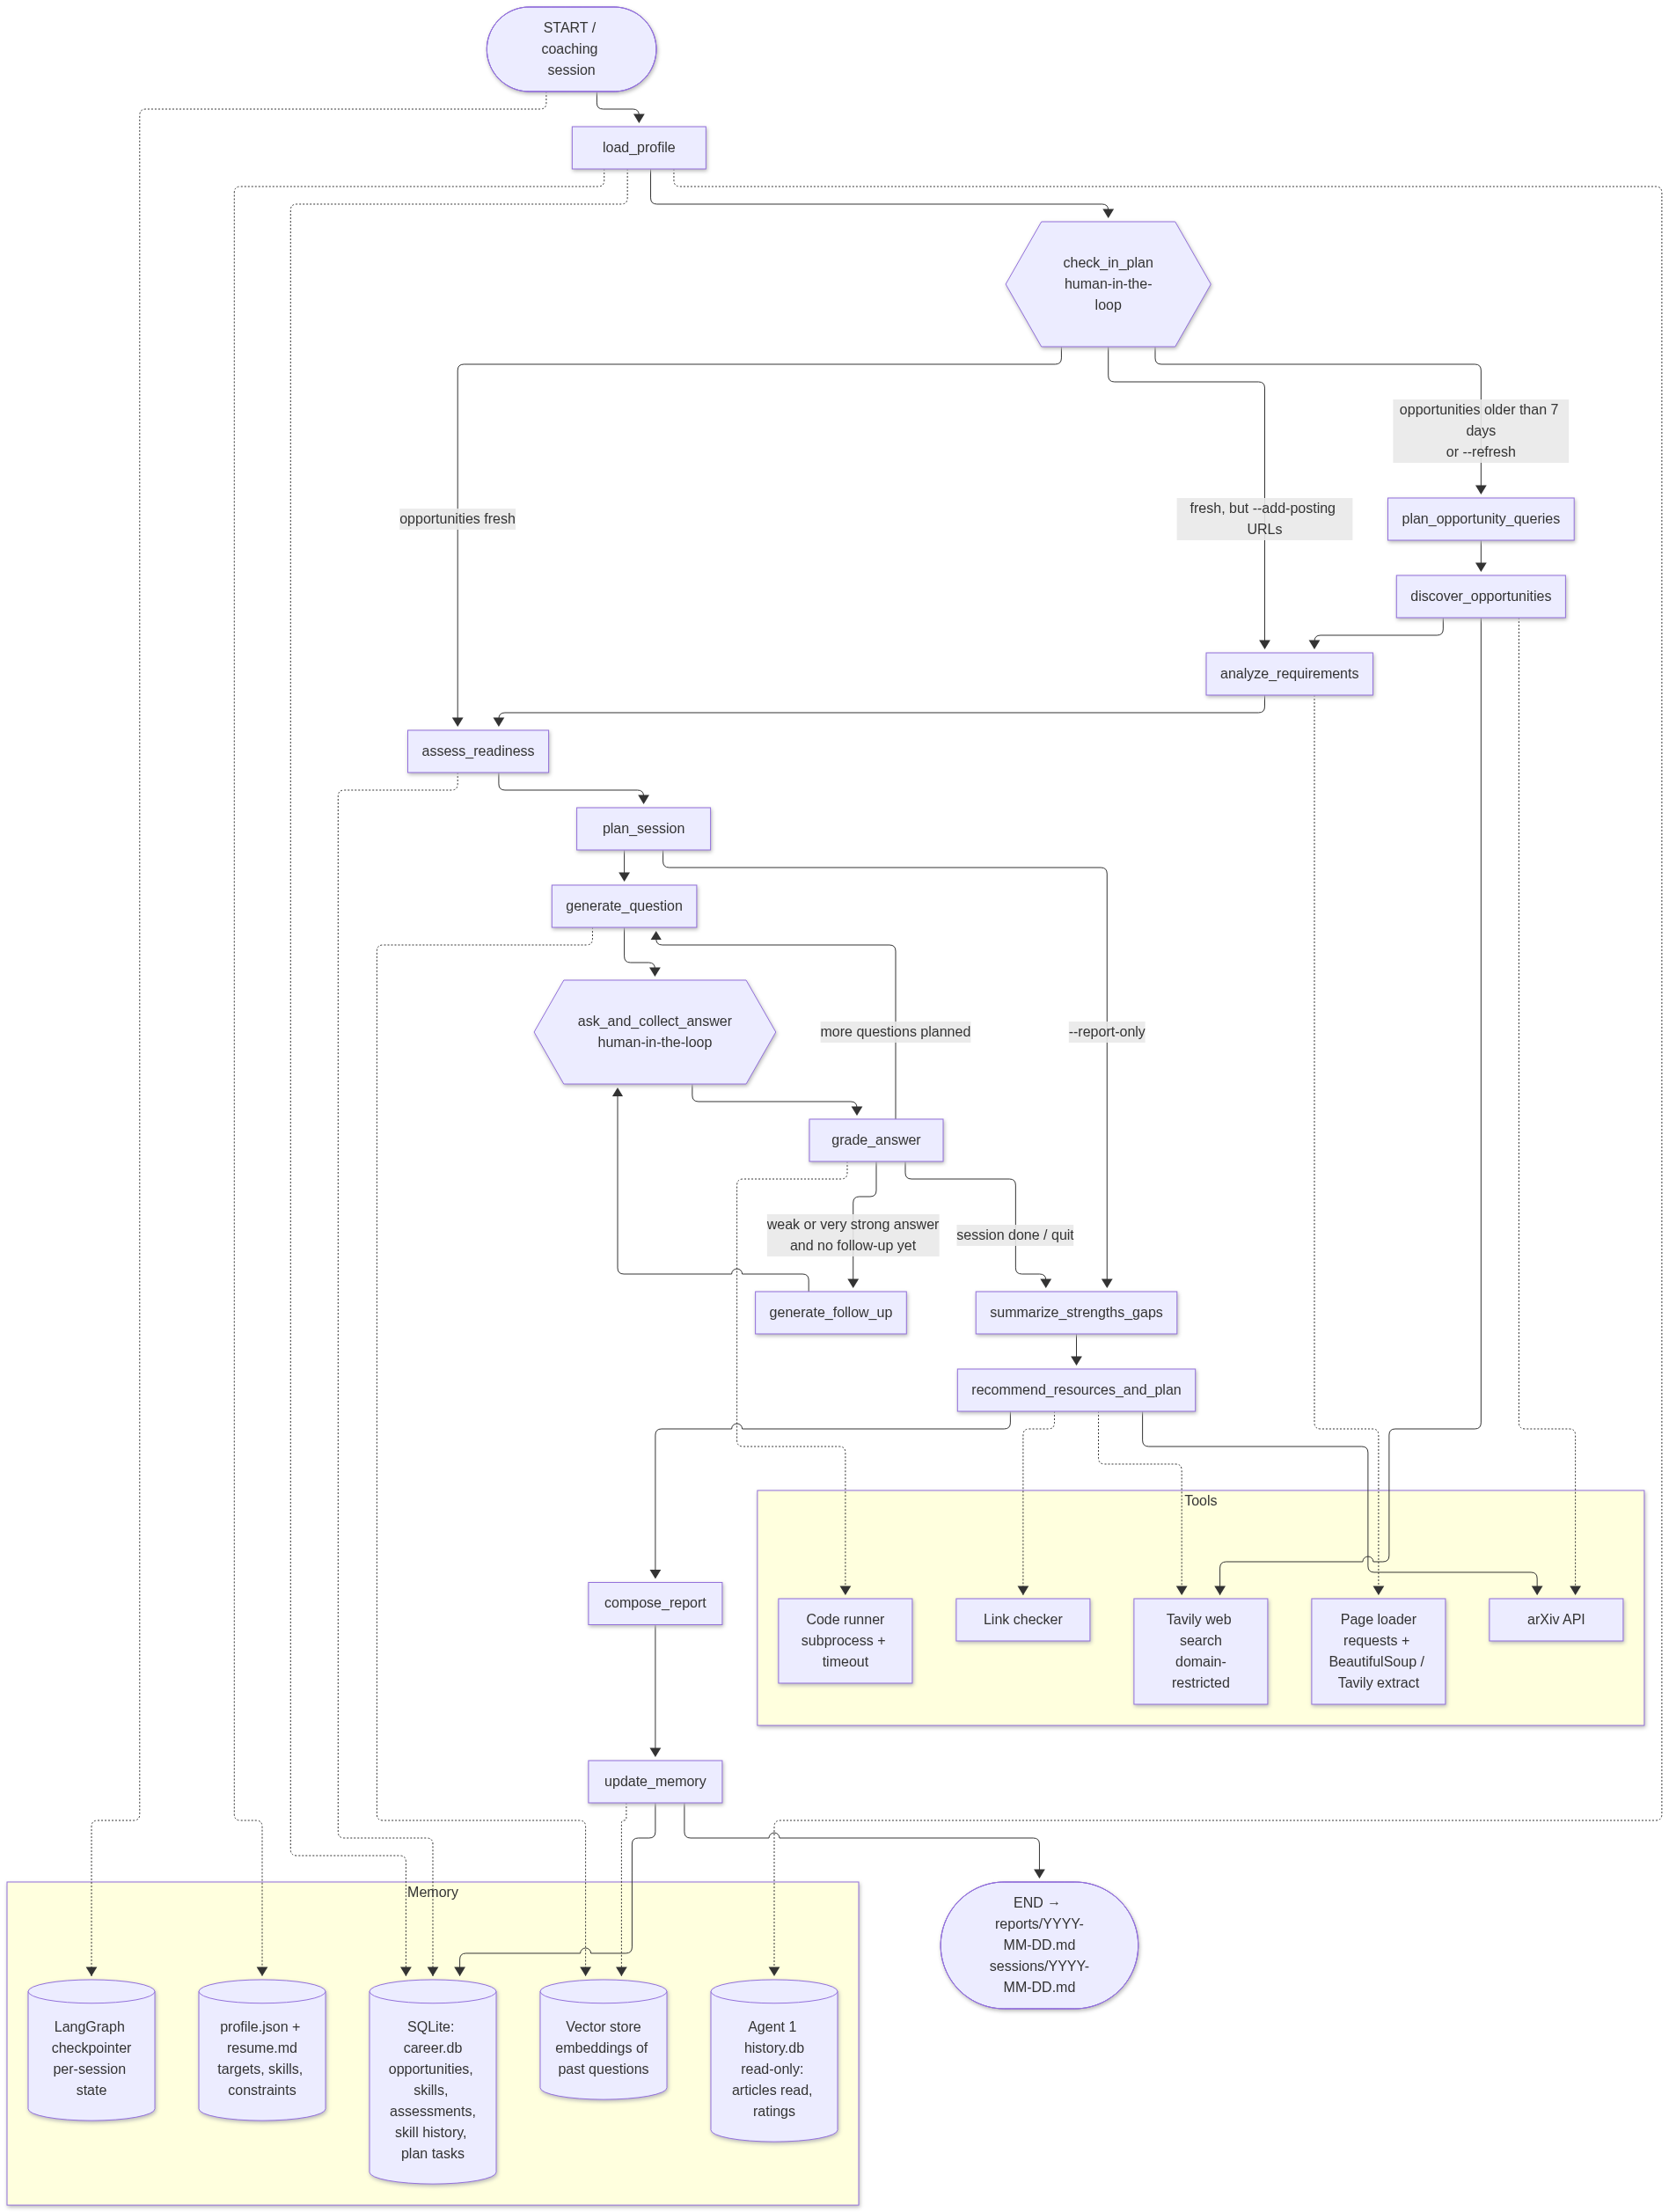

In [1]:
import re
from pathlib import Path

from IPython.display import Image, Markdown, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png

architecture_mermaid = re.search(r"```mermaid\n(.*?)```", Path("ARCHITECTURE.md").read_text(), re.S).group(1)
try:
    display(Image(draw_mermaid_png(architecture_mermaid)))
except Exception as exc:   # rendering uses the mermaid.ink web service
    print(f"Could not render the diagram ({exc}); Mermaid source:\n")
    print(architecture_mermaid)

### 2.2 The compiled graph

The same workflow drawn from the compiled LangGraph object, which confirms the code matches the design. Dotted edges are conditional routes: discovery or not after the check-in, report-only after planning, and follow-up / next question / finish after grading.

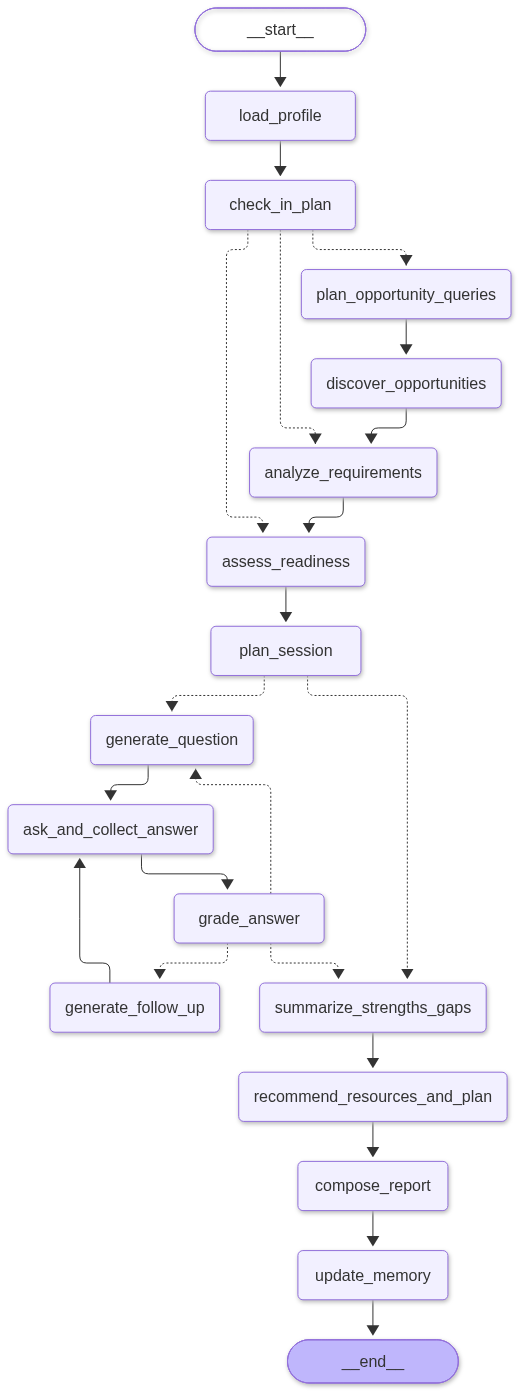

In [2]:
import json
import sys
from collections import Counter
from datetime import date

import config
import evaluate
import memory
import nodes
import tools
from agent import build_graph

app = build_graph()
try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as exc:
    print(f"Could not render the graph ({exc})")
    print(app.get_graph().draw_mermaid())

### 2.3 Nodes

| Node | Type | What it does |
|---|---|---|
| `load_profile` | code | Loads targets, constraints, self-rated skills and projects from `profile.json`; adds reading evidence from Agent 1's `history.db`; loads stored opportunities and open plan tasks |
| `check_in_plan` | human-in-the-loop | Asks the status of each open plan task (done / partial / open / drop); decides whether discovery is due |
| `plan_opportunity_queries` | LLM | Writes 4–8 search queries covering every target type |
| `discover_opportunities` | tools | Domain-restricted Tavily searches over allow-listed job boards and research / entrepreneurial sites; keeps single postings only (URL pattern per job board) |
| `analyze_requirements` | LLM + code | Loads each posting; extracts skill requirements with a quoted evidence line, mapped to `skills.yaml`; drops closed, expired, non-postings and ineligible ones; code computes fit |
| `assess_readiness` | code | Skill demand over the top 10 opportunities; readiness per skill from graded answers (recency-weighted), else self-rating, plus a small reading bonus; gap per skill |
| `plan_session` | code | 5 question slots on the largest gaps, one retest of a weak skill, at least one coding and one scenario question; difficulty from readiness |
| `generate_question` | LLM | Question grounded in a posting requirement or an article I read, with hidden reference answer and rubric; coding questions get starter code, pytest tests (validated against a reference solution) and hints; repeats rejected by embedding similarity |
| `ask_and_collect_answer` | human-in-the-loop | Shows the question and the previous grade; I write the answer in a workspace file (`<id>.md` for text, `<id>.py` for code) and press Enter; `hint`, `skip`, `quit` |
| `grade_answer` | LLM + code | Rubric scores 1–5 against the reference and misconceptions; tests run in a subprocess for code; code computes the 0–1 score and hint penalty |
| `generate_follow_up` | LLM | Score < 0.6: a probing question on the misconception. Score ≥ 0.85: a harder variant. At most one per question |
| `summarize_strengths_gaps` | LLM + code | Updates readiness with today's scores; strengths and gaps must cite question ids or posting requirements (uncited findings are dropped) |
| `recommend_resources_and_plan` | LLM + tools | Searches learning resources for the top gaps, keeps those whose links resolve; writes a 2-week plan; carries over unfinished tasks |
| `compose_report` | code | Renders the report and transcript; titles, URLs and dates come from stored fields |
| `update_memory` | code | Writes opportunities, questions, assessments, readiness and plan tasks to SQLite and question embeddings to the vector store |

### 2.4 Tools

| Tool | Purpose |
|---|---|
| `search_opportunities` | Tavily search for one opportunity type over the allow-listed sources; rejects listing pages and company boards |
| `load_posting` | Posting text; Workday postings come from Workday's JSON endpoint, which also says whether it still accepts applications |
| `posting_is_open` | Closed if the deadline passed, the board says so, or the text says so |
| `search_resources` | Tavily search over allow-listed learning-resource domains |
| `run_tests` | pytest on my code in a temporary directory with a timeout and no API keys; per-test results from JUnit XML |
| `load_page`, `url_resolves`, `search_arxiv` | Reused from Agent 1 |

### 2.5 Data sources

Opportunity and learning-resource domains from `opportunity_sources.yaml`, and the skill taxonomy that requirements are mapped to:

In [3]:
sources = config.load_opportunity_sources()
rows = ["| Source | Types | Domains | Single-posting URL pattern |", "|---|---|---|---|"]
for s in sources["opportunity_sources"]:
    rows.append(f"| {s['name']} | {', '.join(s['types'])} | {', '.join(s['domains'])} | {'`' + s['posting_path'] + '`' if s.get('posting_path') else '–'} |")
resources = ", ".join(s["name"] for s in sources["resource_sources"])
skills = config.load_skills()
taxonomy = "\n".join(f"| {area} | {', '.join(ids)} |" for area, ids in skills["areas"].items())
display(Markdown(
    f"**{len(sources['opportunity_sources'])} opportunity sources** (LinkedIn and Handshake need a login, so postings from them are added with `--add-posting <url>`):\n\n"
    + "\n".join(rows)
    + f"\n\n**Learning resources:** {resources}, Agent 1's sources, and arXiv ({', '.join(sources['arxiv_categories'])}).\n\n"
    + f"**Skill taxonomy** ({sum(len(v) for v in skills['areas'].values())} skills, each with aliases):\n\n| Area | Skills |\n|---|---|\n" + taxonomy
))

**12 opportunity sources** (LinkedIn and Handshake need a login, so postings from them are added with `--add-posting <url>`):

| Source | Types | Domains | Single-posting URL pattern |
|---|---|---|---|
| Greenhouse | internship, job | job-boards.greenhouse.io, boards.greenhouse.io | `^/[^/]+/jobs/\d+` |
| Lever | internship, job | jobs.lever.co | `^/[^/]+/[0-9a-f-]{36}` |
| Ashby | internship, job | jobs.ashbyhq.com | `^/[^/]+/[0-9a-f-]{36}` |
| Workday | internship, job | myworkdayjobs.com | `/job/` |
| NASA internships | internship, research | intern.nasa.gov | – |
| NSF REU | research | nsf.gov | – |
| AAS Job Register | research, job | jobregister.aas.org | – |
| APS careers | research, job | aps.org | – |
| Y Combinator | entrepreneurial | ycombinator.com | `^/(apply|companies/[^/]+/jobs/)` |
| Devpost hackathons | entrepreneurial | devpost.com | – |
| SBIR / STTR | entrepreneurial | sbir.gov | – |
| SJSU | research, entrepreneurial | sjsu.edu | – |

**Learning resources:** LangChain / LangGraph docs, PyTorch docs, scikit-learn docs, Hugging Face Learn, Google ML courses, Microsoft Learn, AWS docs, Astropy docs, Agent 1's sources, and arXiv (cs.LG, cs.AI, cs.CL, astro-ph.IM, astro-ph.GA, astro-ph.CO).

**Skill taxonomy** (30 skills, each with aliases):

| Area | Skills |
|---|---|
| programming | python, algorithms_data_structures, software_engineering, testing, git, sql |
| ml | machine_learning, deep_learning, model_evaluation, recommender_systems, data_analysis, probability_statistics, linear_algebra_calculus |
| llm | llm_fundamentals, rag, llm_agents, langgraph, llm_evaluation, fine_tuning |
| systems | system_design, cloud_platforms, mlops, backend_apis |
| science | physics_fundamentals, astrophysics, observational_data_analysis, scientific_python, ml_for_science, research_methods |
| communication | technical_communication |

### 2.6 Memory

| Store | Kind | Contents | Used for |
|---|---|---|---|
| `profile.json` (+ optional `resume.md`) | long-term, user-edited | targets with type, timeline and priority; constraints; self-rated skills; projects | queries, eligibility, fallback readiness, question context |
| `data/career.db` (SQLite) | long-term, agent-written | opportunities, requirements, posting texts, questions, assessments, skill history, plan tasks | readiness, gaps, check-ins, progress, evaluation |
| Agent 1 `data/history.db` | long-term, read-only | articles I read and my ratings | reading evidence; questions grounded in articles I read |
| `data/question_vectors.json` | long-term semantic | embeddings of past questions (`InMemoryVectorStore`) | rejecting repeated questions |
| `data/checkpoints.db` | per session | full graph state per `thread_id` = session date (`SqliteSaver`) | pausing at `interrupt()`, resuming an unfinished session, evaluation |

Current contents:

In [4]:
conn = memory.connect()
counts = {t: conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
          for t in ("opportunities", "requirements", "posting_texts", "questions", "assessments", "skill_history", "plan_tasks")}
status = dict(conn.execute("SELECT status, COUNT(*) FROM opportunities GROUP BY status").fetchall())
sessions = evaluate.load_sessions()
agent1_db = config.AGENT_DIR.parent / "agent1_daily_tech_upgrade" / "data" / "history.db"
display(Markdown("\n".join([
    f"- `career.db`: {counts['opportunities']} opportunities analyzed ({', '.join(f'{n} {s}' for s, n in status.items())}), "
    f"{counts['requirements']} requirements, {counts['questions']} questions, {counts['assessments']} assessments, "
    f"{counts['skill_history']} readiness points, {counts['plan_tasks']} plan tasks",
    f"- `checkpoints.db`: {len(sessions)} finished session(s) ({', '.join(s['session_date'].isoformat() for s in sessions) or 'none'})",
    f"- `question_vectors.json`: {'present' if config.VECTOR_STORE_PATH.exists() else 'not created yet'}",
    f"- Agent 1 `history.db`: {'present' if agent1_db.exists() else 'missing (no reading evidence)'}",
])))

- `career.db`: 20 opportunities analyzed (9 dismissed, 11 open), 107 requirements, 8 questions, 8 assessments, 22 readiness points, 7 plan tasks
- `checkpoints.db`: 1 finished session(s) (2026-11-01)
- `question_vectors.json`: present
- Agent 1 `history.db`: present

### 2.7 Scoring

All scores are computed in code from the LLM's structured outputs (details in [ARCHITECTURE.md §7](ARCHITECTURE.md)):

- **Answer score** (0–1): mean of `(criterion − 1) / 4` over the rubric criteria, each scored 1–5 by the grader; for code, `0.6 · test pass rate + 0.4 · review`; minus 0.1 per hint.
- **Readiness** per skill: recency-weighted mean of answer scores (half-life 21 days), scaled by question difficulty (0.6 / 0.8 / 1.0); a skill with no graded answers falls back to my self-rating (beginner 0.3, intermediate 0.5, advanced 0.7). Reading in Agent 1 adds up to 0.05.
- **Fit** of a posting: `priority × (0.5 + 0.5 × skill overlap)`. **Demand** per skill: fit-weighted, required counting double, normalized to 1.
- **Gap** = `demand × max(0, target − readiness)`, with the target set by the level the postings ask for (0.5 / 0.7 / 0.85). **Role readiness**: demand-weighted mean of `min(readiness / target, 1)`.

## 3. Working prototype

The coaching session is interactive, so it runs in a terminal:

```
$ python agent.py
Plan check-in: [d]one, [p]artial, [o]pen (Enter), or [x] drop
  Read the RAG guide (due 2026-11-05): d

Question 1/5 · algorithms_data_structures · coding · difficulty 1

<question>

Write your solution in .../workspace/<date>-q1.py, save it, then press Enter.
Commands: hint, skip, quit
>
```

Text questions work the same way with `workspace/<id>.md`, which holds the question and a marker line to write the answer under; an untouched file isn't submitted.

Each pause is a LangGraph `interrupt()`; the CLI reads my answer from the file and resumes the graph with `Command(resume=answer)`. The state is checkpointed after every step, so a closed terminal resumes at the same question. This section walks through the most recent session, stage by stage, from the graph state saved by the checkpointer, and re-runs the code checks live.

### 3.1 Profile and learning evidence

In [5]:
if not sessions:
    raise SystemExit("No finished session saved yet: run `python agent.py` in a terminal first.")
s = sessions[-1]
DEMO_DATE = s["session_date"]
print("Chat model:     ", config.CHAT_MODEL)
print("Embedding model:", config.EMBEDDING_MODEL)
print("Session shown:  ", DEMO_DATE)

profile = s["profile"]
c = profile["constraints"]
display(Markdown(
    f"**{profile['name']}**, {profile['role']}. Education: {'; '.join(profile['education'])}.\n\n"
    "| Target | Type | Timeline | Priority |\n|---|---|---|---|\n"
    + "\n".join(f"| {t['role']} | {t['type']} | {t.get('timeline') or '–'} | {t['priority']} |" for t in profile["targets"])
    + f"\n\n**Constraints:** {'; '.join(c['locations'])}; remote OK: {c['remote_ok']}; {c['work_authorization']}; start: {c['earliest_start']}\n\n"
    + "**Self-rated skills:** " + ", ".join(f"{k} ({v})" for k, v in profile["skills"].items())
    + "\n\n**Projects:** " + "; ".join(profile["projects"])
))
reading = profile.get("reading", {})
display(Markdown(
    "**Reading evidence from Agent 1** (articles read per skill, mapped through the taxonomy aliases):\n\n"
    "| Skill | Articles | My mean rating | Latest |\n|---|---|---|---|\n"
    + "\n".join(f"| {k} | {v['articles']} | {v['avg_rating'] or '–'} | {v['recent'][0]['title'][:70] if v['recent'] else '–'} |"
                 for k, v in sorted(reading.items(), key=lambda kv: -kv[1]["articles"]))
    if reading else "No reading evidence (Agent 1's history.db is missing or empty)."
))

Chat model:      anthropic:claude-opus-5-5
Embedding model: openai:text-embedding-3-small
Session shown:   2026-11-01


**Anita**, MS Software Engineering student, SJSU. Education: BS in Astrophysics; MS in Software Engineering, SJSU (in progress).

| Target | Type | Timeline | Priority |
|---|---|---|---|
| ML / AI engineer intern | internship | summer 2027 | 1.0 |
| Applied AI / LLM agent engineer | job | – | 0.6 |
| Physics / astrophysics research assistant (ML for astronomy) | research | summer 2027 | 0.9 |
| Physics / astrophysics PhD program | research | fall 2028 | 0.8 |
| AI startup programs and hackathons | entrepreneurial | – | 0.3 |

**Constraints:** San Francisco Bay Area, CA (internships and jobs); Europe (research); anywhere in the US (research); remote OK: True; US citizen; start: immediately

**Self-rated skills:** python (advanced), software_engineering (advanced), git (advanced), machine_learning (intermediate), deep_learning (intermediate), probability_statistics (intermediate), linear_algebra_calculus (advanced), sql (intermediate), cloud_platforms (beginner), langgraph (beginner), physics_fundamentals (advanced), astrophysics (intermediate), observational_data_analysis (intermediate), scientific_python (intermediate)

**Projects:** Implementing machine learning classification and regression models to reduce computational cost of particle energy estimation; On Using Neutrino-Driven Supernova Simulation to Interpret Observations; Visualization and Interpolation of Field Mapping Data; AI-Powered Cat Trap Game

**Reading evidence from Agent 1** (articles read per skill, mapped through the taxonomy aliases):

| Skill | Articles | My mean rating | Latest |
|---|---|---|---|
| astrophysics | 5 | 3.5 | JWST reveals a distant galaxy that may let most of its ionizing radiat |
| llm_agents | 3 | 3.33 | Locating and Closing Information Gaps in Multi-Agent Systems |
| rag | 1 | – | Context as Infrastructure: Knowledge Compilation for Retrieval in Agen |
| algorithms_data_structures | 1 | – | Automated inverse design of metainterfaces with tailored friction laws |
| technical_communication | 1 | 3.0 | Locating and Closing Information Gaps in Multi-Agent Systems |
| ml_for_science | 1 | 3.0 | Field-level inference under pressure: the information content of the t |
| langgraph | 1 | 3.0 | The Art of Loop Engineering |

### 3.2 Opportunity discovery

The planned searches and the funnel: candidates found, then postings kept or dropped after `analyze_requirements` read them.

In [6]:
queries = s.get("queries") or []
rejected = Counter(o["status"] for o in s.get("rejected", []))
opps = s["opportunities"]
display(Markdown(
    ("**Queries (Tavily, allow-listed domains):**\n\n| Type | Query |\n|---|---|\n"
     + "\n".join(f"| {q['type']} | {q['query']} |" for q in queries)
     if queries else "Discovery was not due this session (stored opportunities were fresh).")
    + f"\n\n- candidates found: **{len(s.get('candidates', []))}**\n"
    f"- dropped after reading: **{sum(rejected.values())}** ({', '.join(f'{n} {k}' for k, n in rejected.items()) or 'none'})\n"
    f"- open opportunities used: **{len(opps)}** (by type: {', '.join(f'{k} {n}' for k, n in Counter(o['type'] for o in opps).items())})"
))
rows = ["| # | Opportunity | Org | Type | Deadline | Fit |", "|---|---|---|---|---|---|"]
for i, o in enumerate(opps[:10], 1):
    rows.append(f"| {i} | [{nodes.md_cell(o['title'])[:80]}]({o['url']}) | {nodes.md_cell(o.get('org') or '–')[:40]} | "
                f"{o['type']} | {nodes.fmt_date(o.get('deadline'))} | {o['fit_score']:.2f} |")
display(Markdown("\n".join(rows)))

**Queries (Tavily, allow-listed domains):**

| Type | Query |
|---|---|
| internship | machine learning engineer intern summer 2027 San Francisco Bay Area apply |
| internship | AI engineer intern summer 2027 LLM master's student Bay Area OR remote job posting |
| job | applied AI engineer LLM agents LangGraph entry level San Francisco OR remote job opening |
| research | astrophysics machine learning research assistant summer 2027 application open |
| research | summer 2027 research internship astronomy machine learning Europe OR US undergraduate graduate students apply |
| research | astrophysics PhD program fall 2028 admissions machine learning computational astrophysics |
| entrepreneurial | AI hackathon 2026 San Francisco OR online registration open LLM agents |
| entrepreneurial | AI startup accelerator program for student founders 2026 application open |

- candidates found: **20**
- dropped after reading: **9** (9 dismissed)
- open opportunities used: **11** (by type: internship 7, research 1, job 3)

| # | Opportunity | Org | Type | Deadline | Fit |
|---|---|---|---|---|---|
| 1 | [Simbe Robotics - Computer Vision / Applied AI Intern — Summer 2027](https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8) | Simbe Robotics | internship | not stated | 0.78 |
| 2 | [Machine Learning Engineer Intern - Summer 2027](https://job-boards.greenhouse.io/imc/jobs/4962456101) | IMC | internship | not stated | 0.75 |
| 3 | [2027 Summer Intern – Machine Learning Intern, Autonomous Vehicles: Software Vali](https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Intern--Autonomous-Vehicles--Software-Validation--Master-s-_JR-202621655) | General Motors | internship | not stated | 0.75 |
| 4 | [2027 Summer Intern – Machine Learning Engineer, AV/AI Platform](https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Engineer--AV-AI-Platform_JR-202621695) | General Motors (AV/AI Platform) | internship | not stated | 0.73 |
| 5 | [Astronomy and Astrophysics Research Grants (MPS Astro) \| NSF - U.S. National Sc](https://www.nsf.gov/funding/opportunities/mps-astro-mps-astronomical-sciences-research-programs/nsf22-624) | U.S. National Science Foundation, Divisi | research | not stated | 0.72 |
| 6 | [Machine Learning Research Intern (Summer 2027)](https://job-boards.greenhouse.io/scaleai/jobs/4735665005) | Scale AI | internship | not stated | 0.71 |
| 7 | [Summer 2027 AI Engineer Intern](https://job-boards.greenhouse.io/datacor/jobs/5242412007) | Datacor | internship | not stated | 0.70 |
| 8 | [Simbe Robotics - Hardware / Mechanical Engineering Intern — Spring & Summer 2027](https://jobs.lever.co/SimbeRobotics/715377a7-1dc0-41b9-8146-ac2d2d752ca3) | Simbe Robotics | internship | not stated | 0.50 |
| 9 | [Mid-Level AI Engineer](https://jobs.ashbyhq.com/clera/d8366414-d411-4b2d-8f6d-fe37b37bbddc) | Clera | job | not stated | 0.38 |
| 10 | [Software Engineer - Applied AI](https://jobs.ashbyhq.com/titan-msp/1cb431df-d44a-4407-a173-5338dc11de11) | Titan | job | not stated | 0.35 |

### 3.3 Requirements with evidence

The LLM maps each requirement to a skill id and copies the line that states it; `evaluate.py` later checks that the line really is in the posting text. Requirements of the most detailed posting among the top five:

In [7]:
top = max(opps[:5], key=lambda o: len(o["requirements"]))
reqs = sorted(top["requirements"], key=lambda r: (not r["required"], -r["level"]))
display(Markdown(
    f"**[{top['title']}]({top['url']})**: {len(reqs)} requirements, "
    f"{sum(not r['skill'].startswith('other:') for r in reqs)} mapped to the taxonomy\n\n"
    "| Skill | Level | Required | Evidence (quoted from the posting) |\n|---|---|---|---|\n"
    + "\n".join(f"| {r['skill']} | {r['level']} | {'yes' if r['required'] else 'preferred'} | {nodes.md_cell(r['evidence'])[:160]} |"
                 for r in reqs)
))

**[Simbe Robotics - Computer Vision / Applied AI Intern — Summer 2027](https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8)**: 15 requirements, 12 mapped to the taxonomy

| Skill | Level | Required | Evidence (quoted from the posting) |
|---|---|---|---|
| python | 3 | yes | Strong Python programming skills, including familiarity with common data structures, algorithms, and software development practices. |
| algorithms_data_structures | 2 | yes | Strong Python programming skills, including familiarity with common data structures, algorithms, and software development practices. |
| machine_learning | 2 | yes | Coursework or hands-on experience in computer vision, machine learning, or deep learning. |
| deep_learning | 2 | yes | Experience with PyTorch, TensorFlow, or a comparable machine learning framework. |
| software_engineering | 2 | yes | Experience working with structured Python projects beyond notebooks alone. |
| data_analysis | 2 | yes | Comfortable working with data to evaluate results, investigate failures, and support technical decisions. |
| git | 1 | yes | Familiarity with Git or another source-control system. |
| other:computer_vision | 2 | preferred | Experience with object detection, image segmentation, OCR, barcode recognition, image classification, or related vision problems. |
| other:image_dataset_curation | 2 | preferred | Experience creating, cleaning, curating, or evaluating image datasets. |
| scientific_python | 2 | preferred | Experience with pandas, NumPy, OpenCV, Jupyter, SQL, or related data and ML tooling. |
| sql | 2 | preferred | Experience with pandas, NumPy, OpenCV, Jupyter, SQL, or related data and ML tooling. |
| model_evaluation | 1 | preferred | Familiarity with model evaluation techniques, error analysis, experiment tracking, or data-quality workflows. |
| mlops | 1 | preferred | Familiarity with Linux, shell scripting, Docker, or cloud-based development environments. |
| cloud_platforms | 1 | preferred | Familiarity with Linux, shell scripting, Docker, or cloud-based development environments. |
| other:ai_assisted_coding | 1 | preferred | Experience with AI-assisted coding and engineering tools and the ability to thoughtfully validate generated output. |

### 3.4 Readiness, gaps and the session plan

Demand from the top opportunities against my readiness before the session; the planner turns the largest gaps into question slots.

In [8]:
assessed = set(s.get("assessed_skills", []))
gaps = nodes.skill_gaps(s["skill_demand"], s["skill_targets"], s["readiness"])
rows = ["| Skill | Demand | Level asked | Readiness | Basis | Gap |", "|---|---|---|---|---|---|"]
for skill, gap in list(gaps.items())[:12]:
    rows.append(f"| {skill} | {s['skill_demand'][skill]:.2f} | {s['skill_targets'][skill]} | {nodes.pct(s['readiness'].get(skill, 0.0))} | "
                f"{nodes.readiness_basis(skill, assessed, profile, s['readiness'])} | {gap:.2f} |")
display(Markdown("**Largest gaps**\n\n" + "\n".join(rows)))
display(Markdown("**Session plan**\n\n| # | Skill | Kind | Difficulty | Why |\n|---|---|---|---|---|\n" + "\n".join(
    f"| {i} | {p['skill']} | {p['kind']} | {p['difficulty']} | {p.get('reason', 'gap')} |" for i, p in enumerate(s["session_plan"], 1))))

**Largest gaps**

| Skill | Demand | Level asked | Readiness | Basis | Gap |
|---|---|---|---|---|---|
| algorithms_data_structures | 0.51 | 3 | 1% | reading only | 0.43 |
| research_methods | 0.35 | 3 | 0% | no evidence | 0.30 |
| llm_fundamentals | 0.34 | 3 | 0% | no evidence | 0.29 |
| mlops | 0.35 | 2 | 0% | no evidence | 0.25 |
| llm_agents | 0.28 | 3 | 3% | reading only | 0.23 |
| system_design | 0.21 | 3 | 0% | no evidence | 0.18 |
| python | 1.00 | 3 | 70% | self-rated | 0.15 |
| llm_evaluation | 0.21 | 2 | 0% | no evidence | 0.15 |
| fine_tuning | 0.17 | 3 | 0% | no evidence | 0.15 |
| rag | 0.21 | 2 | 1% | reading only | 0.14 |
| machine_learning | 0.64 | 2 | 50% | self-rated | 0.13 |
| backend_apis | 0.14 | 3 | 0% | no evidence | 0.12 |

**Session plan**

| # | Skill | Kind | Difficulty | Why |
|---|---|---|---|---|
| 1 | algorithms_data_structures | coding | 1 | gap |
| 2 | research_methods | scenario | 1 | gap |
| 3 | llm_fundamentals | concept | 1 | gap |
| 4 | mlops | concept | 1 | gap |
| 5 | llm_agents | concept | 1 | gap |

### 3.5 The question loop

Every question asked, how I responded, and the score. A follow-up is asked when an answer scores below 0.6 (probe) or at least 0.85 (challenge).

In [9]:
by_question = {a["question_id"]: a for a in s.get("assessments", [])}
scores = {qid: a.get("score") for qid, a in by_question.items()}
rows = ["| Question | Skill | Kind | Difficulty | Follow-up | Response | Score | Tests | Hints |", "|---|---|---|---|---|---|---|---|---|"]
for q in s["questions"]:
    a = by_question.get(q["id"])
    parent = q.get("parent_id")
    mode = nodes.follow_up_mode(scores[parent]) if parent and scores.get(parent) is not None else None
    response = a["action"] if a else "not answered (quit)"
    score = f"{a['score']:.2f}" if a and a.get("score") is not None else "–"
    tests = f"{a['tests_passed']:.0%}" if a and a.get("tests_passed") is not None else "–"
    rows.append(f"| {q['id']} | {q['skill']} | {q['kind']} | {q['difficulty']} | {mode or '–'} | {response} | {score} | {tests} | "
                f"{a.get('hints_used', 0) if a else '–'} |")
display(Markdown("\n".join(rows) + ("\n\n_I ended the session early._" if s.get("quit") else "")))

| Question | Skill | Kind | Difficulty | Follow-up | Response | Score | Tests | Hints |
|---|---|---|---|---|---|---|---|---|
| 2026-11-01-q1 | algorithms_data_structures | coding | 1 | – | answered | 0.95 | 100% | 0 |
| 2026-11-01-q1f | algorithms_data_structures | concept | 2 | challenge | answered | 0.83 | – | 0 |
| 2026-11-01-q2 | research_methods | scenario | 1 | – | answered | 0.94 | – | 0 |
| 2026-11-01-q2f | research_methods | scenario | 2 | challenge | answered | 0.92 | – | 0 |
| 2026-11-01-q3 | llm_fundamentals | concept | 1 | – | answered | 0.81 | – | 0 |
| 2026-11-01-q4 | mlops | concept | 1 | – | answered | 0.81 | – | 0 |
| 2026-11-01-q5 | llm_agents | concept | 1 | – | answered | 0.94 | – | 0 |
| 2026-11-01-q5f | llm_agents | concept | 2 | challenge | answered | 0.75 | – | 0 |

### 3.6 Grading an answer

The grader sees the question, the hidden reference answer, the rubric and (for code) the test results. One graded answer in full, with its follow-up:

In [10]:
answered = [a for a in s.get("assessments", []) if a["action"] == "answered"]
questions = {q["id"]: q for q in s["questions"]}
if answered:
    with_follow_up = [a for a in answered if any(q.get("parent_id") == a["question_id"] for q in s["questions"])]
    a = (with_follow_up or answered)[0]
    q = questions[a["question_id"]]
    follow_up = next((f for f in s["questions"] if f.get("parent_id") == q["id"]), None)
    lines = [f"**{q['id']} · {q['skill']} · {q['kind']} · difficulty {q['difficulty']}**", "",
             "| Rubric criterion | Score (1–5) |", "|---|---|"]
    lines += [f"| {nodes.md_cell(c)} | {v} |" for c, v in a["criteria_scores"].items()]
    lines += ["", f"**Score {a['score']:.2f}**" + (f" (tests passed: {a['tests_passed']:.0%})" if a.get("tests_passed") is not None else ""),
              "", f"**Feedback:** {a['feedback']}"]
    if a.get("misconceptions"):
        lines += ["", "**Misconceptions:**"] + [f"- {m}" for m in a["misconceptions"]]
    if follow_up:
        fa = by_question.get(follow_up["id"])
        lines += ["", f"**Follow-up ({nodes.follow_up_mode(a['score'])}):** {follow_up['prompt']}", "",
                  f"Follow-up score: {fa['score']:.2f}" if fa and fa.get("score") is not None else "Follow-up not answered."]
    display(Markdown("\n".join(lines)))
else:
    print("No answered questions in this session.")

**2026-11-01-q1 · algorithms_data_structures · coding · difficulty 1**

| Rubric criterion | Score (1–5) |
|---|---|
| Correctness: sorts by start, merges overlapping and touching windows using max of ends (handles nested windows), and returns tuples in sorted order. | 5 |
| Edge cases: empty input, single window, touching boundaries, and fully contained windows are all handled; the input list is not mutated. | 5 |
| Complexity: correctly identifies O(n log n) time dominated by the sort and O(n) extra space, and explains why one linear pass suffices after sorting. | 3 |
| Code quality: clear, idiomatic Python (sorted with key, unpacking, readable variable names) with no unnecessary nested loops. | 5 |

**Score 0.95** (tests passed: 100%)

**Feedback:** Your implementation is correct and clean. It sorts a copy, merges touching windows with `<=`, handles nested windows with `max`, returns tuples, and handles empty input without mutating the original list. The weak spot is the complexity statement. Two bare comments, `# O(n log n)` and `# O(n)`, don't say which is time and which is space, and they don't explain the reasoning. Next time, say that time is O(n log n), dominated by the sort, with an O(n) sweep after it. Say that space is O(n) for the sorted copy and the output. Then add a sentence on why one greedy pass is enough: after sorting by start, any window that overlaps the current merged block must come immediately after it.

**Misconceptions:**
- Complexity is stated without labeling time versus space and without justifying why a single linear pass after sorting is sufficient.

**Follow-up (challenge):** Your merge_windows solution sorts all windows and then does one linear pass. Now suppose the scheduler runs continuously: new observation windows arrive one at a time (possibly out of order), and after each arrival the operator may ask for the current merged schedule or ask "is time t covered?". There could be millions of windows over a night. Re-sorting and re-merging the whole list on every update would be O(n log n) per update. How would you redesign this to handle incremental inserts and coverage queries efficiently? Describe the data structure, how an insert works (including when a new window bridges or swallows several existing merged windows), the time complexity per insert and per query, and why it's correct. Along the way, explain clearly why, in your original solution, a single pass after sorting is enough—that is, why comparing only against the last merged window never misses a merge.

Follow-up score: 0.83

### 3.7 Running the coding tests live

Generated tests are first run against the hidden reference solution, and tests it fails are dropped, so broken tests can't fail correct code. Re-running the code runner now on the reference solution, the untouched starter file, and my submitted answer:

In [11]:
coding = [q for q in s["questions"] if q["kind"] == "coding" and q.get("tests")]
if coding:
    q = coding[0]
    a = by_question.get(q["id"])
    runs = {"reference solution": q["reference_solution"], "starter code": q.get("starter_code") or nodes.EMPTY_STARTER}
    if a and a["action"] == "answered":
        runs["my answer"] = a["answer"]
    rows = ["| Code | Tests passed | Pass rate | Timed out |", "|---|---|---|---|"]
    for name, src in runs.items():
        r = tools.run_tests(src, q["tests"])
        rows.append(f"| {name} | {r['passed']}/{r['total']} | {r['pass_rate']:.0%} | {r['timed_out']} |")
    display(Markdown(f"**{q['id']}** ({len(re.findall(r'^def test_', q['tests'], re.M))} tests)\n\n" + "\n".join(rows)))
else:
    print("No coding question in this session.")

**2026-11-01-q1** (10 tests)

| Code | Tests passed | Pass rate | Timed out |
|---|---|---|---|
| reference solution | 10/10 | 100% | False |
| starter code | 1/10 | 10% | False |
| my answer | 10/10 | 100% | False |

### 3.8 Strengths, gaps and the plan

After the questions, readiness is updated with today's scores. The strengths and gaps below are the LLM's summary after its evidence check: findings citing an unknown question id or requirement are dropped. The plan's resources come from search results whose links resolved.

In [12]:
refs = s.get("requirement_refs", {})
def findings(items):
    return "\n".join(f"- **{f['skill']}**: {f['summary']} _(evidence: {', '.join(f['evidence'])})_" for f in items) or "- none"
display(Markdown("**Strengths**\n\n" + findings(s.get("strengths", [])) + "\n\n**Gaps**\n\n" + findings(s.get("gaps", []))))
plan = s.get("prep_plan", [])
carried = sum(t.get("id") in {o["id"] for o in s.get("open_tasks", [])} for t in plan)
display(Markdown(
    f"**Plan:** {len(plan)} tasks ({carried} carried over), {sum(t.get('hours') or 0 for t in plan):g} hours, "
    f"{len(s.get('resources', []))} resources\n\n| Task | Skill | Hours | Due |\n|---|---|---|---|\n"
    + "\n".join(f"| {nodes.md_cell(t['task'])[:110]} | {t['skill']} | {t.get('hours')} | {nodes.fmt_date(t.get('due'))} |" for t in plan)
))

**Strengths**

- **algorithms_data_structures**: Strong assessed performance (readiness 0.63, assessed): coding answer scored 0.95 and the concept follow-up scored 0.83. This matters for intern postings that require strong algorithms and data structures. One minor issue: complexity was stated without separating time from space, and without justifying why a single linear pass after sorting is sufficient. _(evidence: 2026-11-01-q1, 2026-11-01-q1f, R15, R17, R14)_
- **research_methods**: Excellent scenario answers (0.94, 0.92) with no misconceptions, giving readiness 0.65 (assessed). This supports the research assistant, PhD and research-intern targets, though postings at level 3 also expect a track record of publications that this session cannot show. _(evidence: 2026-11-01-q2, 2026-11-01-q2f, R32, R33, R31)_
- **llm_agents**: Solid assessed understanding of agents (readiness 0.61, assessed): the concept answer scored 0.94 and the follow-up scored 0.75. This is relevant to the applied AI / LLM agent engineer target. _(evidence: 2026-11-01-q5, 2026-11-01-q5f, R36)_
- **mlops**: Concept answer scored 0.81 with no misconceptions, but overall readiness is moderate at 0.49 (assessed). Postings ask for testing, evaluation and monitoring of production AI systems, plus deployment experience. _(evidence: 2026-11-01-q4, R30, R29)_

**Gaps**

- **python**: Python is the most demanded skill (importance 1.0, level 3 asked), but readiness is 0.70 and only self-rated. It was not assessed today, so proficiency at the required level is unverified. _(evidence: R1, R4, R7, R8)_
- **machine_learning**: Readiness is 0.50, self-rated only, with no graded answers. Nearly every intern posting requires an ML foundation. _(evidence: R9, R11, R12, R13)_
- **deep_learning**: Readiness is 0.50, self-rated only. Postings require framework experience (PyTorch/TensorFlow) and a deep learning foundation, and none of this was assessed. _(evidence: R18, R22, R20)_
- **llm_fundamentals**: Readiness is 0.49 (assessed) despite a 0.81 answer, and postings ask for level 3 expertise. Two misconceptions came up:
- Decode slowness was framed only as serial steps; the answer missed that each step is memory-bandwidth-bound, unlike compute-bound prefill.
- The causal mask was justified only for training, not for keeping inference consistent with training. _(evidence: 2026-11-01-q3, R35, R36, R34)_
- **software_engineering**: Readiness is 0.70 but self-rated only. Postings require structured projects beyond notebooks, and one role asks for production engineering experience; none of this was verified this session. _(evidence: R23, R25, R26)_
- **llm_agents**: The follow-up exposed gaps in explaining context-growth trade-offs:
- It did not state that cost explodes because the full history is resent every turn.
- It did not state that quality degrades through attention dilution over long context.
- It omitted prompt-cache invalidation, tool-call/result pairing constraints, and error compounding from repeated summarization. _(evidence: 2026-11-01-q5f)_
- **sql**: Readiness is 0.50, self-rated only. SQL or database proficiency is required in some postings and has not been assessed. _(evidence: R38, R39, R37)_
- **cloud_platforms**: Low self-rated readiness (0.30). Postings mention cloud development environments and AWS/GCP deployment. _(evidence: R40, R29, R7)_

**Plan:** 7 tasks (0 carried over), 19 hours, 6 resources

| Task | Skill | Hours | Due |
|---|---|---|---|
| Study 8 key patterns (Cache-Aside, Queue-Based Load Leveling, Retry, Circuit Breaker, Sharding, CQRS, Publish/ | system_design | 3.0 | Nov 4, 2026 |
| Work through the Google Python class exercises (string1, list1, wordcount) and solve 6 medium coding problems  | python | 3.0 | Nov 6, 2026 |
| Read both LLM evaluation resources and make a comparison table of automatic benchmarks, human evaluation, and  | llm_evaluation | 2.0 | Nov 7, 2026 |
| Do a timed 45-minute mock design of a URL shortener or chat service: requirements, API, data model, high-level | system_design | 2.5 | Nov 8, 2026 |
| Read the fine-tuning guide and fine-tune a small model (e.g. distilbert) on a sentiment dataset such as IMDB w | fine_tuning | 3.0 | Nov 10, 2026 |
| Build a small LLM-as-judge script: score 20 Q&A pairs with a rubric prompt, swap the answer order to measure p | llm_evaluation | 2.5 | Nov 11, 2026 |
| Follow the custom-dataset tutorial to fine-tune for NER or QA on a small custom split, then write notes contra | fine_tuning | 3.0 | Nov 14, 2026 |

## 4. Sample results

Interactive career coaching sessions I ran in the terminal. The report and transcript of each session are committed in [reports/](reports/) and [sessions/](sessions/).

In [13]:
rows = ["| Date | Questions | Follow-ups | Answered | Mean score | Ended early | Report | Transcript |", "|---|---|---|---|---|---|---|---|"]
for r in sessions:
    qs, ans = r["questions"], [a for a in r.get("assessments", []) if a["action"] == "answered"]
    mean = sum(a["score"] for a in ans) / len(ans) if ans else None
    d = r["session_date"].isoformat()
    rows.append(f"| {d} | {len(nodes.top_level_questions(qs))} | {sum(bool(q.get('parent_id')) for q in qs)} | "
                f"{len(ans)}/{len(r.get('assessments', []))} | {f'{mean:.2f}' if mean is not None else '–'} | "
                f"{'yes' if r.get('quit') else 'no'} | [report](reports/{d}.md) | [transcript](sessions/{d}.md) |")
display(Markdown("\n".join(rows)))

| Date | Questions | Follow-ups | Answered | Mean score | Ended early | Report | Transcript |
|---|---|---|---|---|---|---|---|
| 2026-11-01 | 5 | 3 | 8/8 | 0.87 | no | [report](reports/2026-11-01.md) | [transcript](sessions/2026-11-01.md) |

### 4.1 Interactive coaching session

The transcript of the session shown in section 3: each question, my answer, the grade and feedback, the follow-ups, and the hidden reference answer (revealed after the session).

In [14]:
display(Markdown(Path(s["transcript_path"]).read_text()))

# Coaching Session — Nov 1, 2026

Plan: algorithms_data_structures (coding, d1, gap) · research_methods (scenario, d1, gap) · llm_fundamentals (concept, d1, gap) · mlops (concept, d1, gap) · llm_agents (concept, d1, gap)

## 2026-11-01-q1 · algorithms_data_structures · coding · difficulty 1

You're building a small scheduling utility for a telescope (or a robot's sensor log). You're given a list of observation windows, each a tuple (start, end) with start <= end, in arbitrary order. Some windows overlap or touch.

Implement `merge_windows(windows)` that returns a new list of non-overlapping windows covering exactly the same time. Requirements:

- Sort the result by start time.
- Merge windows that share at least one point, so (1, 3) and (3, 5) become (1, 5).
- Return each window as a tuple.
- Return [] for empty input.
- Do not mutate the input list.

After coding, state the time and space complexity of your solution.

_Based on: <https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8>_

Starter code:

```python
def merge_windows(windows):
    """Merge overlapping or touching observation windows.

    Args:
        windows: list of (start, end) tuples with start <= end, in any order.

    Returns:
        A new list of non-overlapping (start, end) tuples sorted by start.
        Windows that share at least one point are merged, e.g.
        (1, 3) and (3, 5) -> (1, 5). Returns [] for empty input.
        The input list must not be modified.
    """
    pass
```

**My answer:**

```python
def merge_windows(windows):
    if not windows:
        return []

    sorted_windows = sorted(windows)
    merged = [tuple(sorted_windows[0])]

    for start, end in sorted_windows[1:]:
        previous_start, previous_end = merged[-1]

        if start <= previous_end:  # Overlap or touching
            merged[-1] = (
                previous_start,
                max(previous_end, end)
            )
        else:
            merged.append((start, end))

    return merged

# O(n log n)
# O(n)
```

**Score:** 0.95 · tests passed 100% · hints used: 0
- 5/5 · Correctness: sorts by start, merges overlapping and touching windows using max of ends (handles nested windows), and returns tuples in sorted order.
- 5/5 · Edge cases: empty input, single window, touching boundaries, and fully contained windows are all handled; the input list is not mutated.
- 3/5 · Complexity: correctly identifies O(n log n) time dominated by the sort and O(n) extra space, and explains why one linear pass suffices after sorting.
- 5/5 · Code quality: clear, idiomatic Python (sorted with key, unpacking, readable variable names) with no unnecessary nested loops.

**Feedback:** Your implementation is correct and clean. It sorts a copy, merges touching windows with `<=`, handles nested windows with `max`, returns tuples, and handles empty input without mutating the original list. The weak spot is the complexity statement. Two bare comments, `# O(n log n)` and `# O(n)`, don't say which is time and which is space, and they don't explain the reasoning. Next time, say that time is O(n log n), dominated by the sort, with an O(n) sweep after it. Say that space is O(n) for the sorted copy and the output. Then add a sentence on why one greedy pass is enough: after sorting by start, any window that overlaps the current merged block must come immediately after it.

**Misconceptions:**
- Complexity is stated without labeling time versus space and without justifying why a single linear pass after sorting is sufficient.

<details><summary>Reference answer</summary>

Sort a copy of the windows by start time with `sorted()`, so the input is not mutated. Then sweep once while keeping the last merged window:

- If the current window's start is <= the last merged end, the two overlap or touch. Extend the end to max(last_end, current_end). Taking the max is required because a window can sit fully inside another, e.g. (1, 10) and (2, 3).
- Otherwise, append the current window as a new merged window.

Convert the results to tuples at the end. Handle empty input up front.

Correctness: after sorting, any window that overlaps the current merged block must come right after it in the sweep. So a single greedy pass is enough.

Complexity: sorting costs O(n log n) and the sweep is O(n), so O(n log n) time overall. Space is O(n) for the sorted copy and the output.

Edge cases:
- empty list
- single window
- touching endpoints
- nested windows
- unsorted input
- zero-length windows

</details>

## Follow-up to 2026-11-01-q1 · algorithms_data_structures · concept · difficulty 2

Your merge_windows solution sorts all windows and then does one linear pass. Now suppose the scheduler runs continuously: new observation windows arrive one at a time (possibly out of order), and after each arrival the operator may ask for the current merged schedule or ask "is time t covered?". There could be millions of windows over a night. Re-sorting and re-merging the whole list on every update would be O(n log n) per update. How would you redesign this to handle incremental inserts and coverage queries efficiently? Describe the data structure, how an insert works (including when a new window bridges or swallows several existing merged windows), the time complexity per insert and per query, and why it's correct. Along the way, explain clearly why, in your original solution, a single pass after sorting is enough—that is, why comparing only against the last merged window never misses a merge.

_Based on: <https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8>_

**My answer:**

> In the original solution, sorting by start time guarantees that every interval encountered later begins no earlier than the intervals already processed. After merging the processed intervals, the last merged interval has the greatest end time among them. Therefore, if the next interval starts after the last merged interval ends, it cannot overlap or touch any earlier interval either, since those intervals end no later than the last one. If it starts at or before the last end, it only needs to be merged with that last interval. This invariant is why comparing only with merged[-1] is sufficient.
> 
> For incremental updates, I would maintain the current merged intervals in an ordered balanced binary search tree keyed by start time. The tree stores only disjoint, non-touching intervals. To insert (start, end), find its predecessor and merge with it if the predecessor’s end is at least start. Then examine successor intervals while their starts are at most the current end, extending end as necessary and removing each absorbed interval. This handles windows that overlap, touch, bridge, or swallow several existing merged intervals. Finally, insert the resulting merged interval into the tree. The operation is correct because any affected interval must be the predecessor or a consecutive successor: intervals before the predecessor end too early, and intervals after the scanned range start too late to connect.
> 
> If m is the number of currently merged intervals and k intervals are absorbed, an insertion takes O(log m + k log m) time with an ordinary balanced tree, with a worst case of O(m log m). Across an insert-only sequence, the amortized cost is O(log n), because each stored interval can be removed only once after being created. A coverage query for time t uses a predecessor lookup and takes O(log m): t is covered exactly when that predecessor’s end is at least t. Returning the entire merged schedule takes O(m) time because all intervals must be output.

**Score:** 0.83 · hints used: 0
- 4/5 · Correctly justifies the single-pass invariant: after sorting by start, later windows cannot reach earlier finalized merged windows, so only the last merged window needs comparison. Labels time O(n log n) and space O(n) explicitly.
- 5/5 · Proposes a sorted ordered structure (balanced BST, SortedList, skip list) holding disjoint merged intervals, and describes an insert that checks the predecessor and absorbs consecutive successors with start ≤ e, respecting touching semantics.
- 4/5 · Gives correct complexities: O(log n) amortized insert, with the reasoning that each interval is removed at most once; O(log n) point-coverage query; and notes trade-offs such as list+bisect shifting cost or the difficulty of supporting deletions.

**Feedback:** Your single-pass justification is sound: later windows start later, and the last merged window has the largest end, so earlier merged windows are finalized. Your BST design is also correct, with the right predecessor check, successor absorption using ≤ for touching windows, and a clear correctness argument. Your insert and query complexities are right, including the amortized argument that each interval is removed at most once. To improve, state the batch cost explicitly: O(n log n) time and O(n) space. Also discuss trade-offs, such as a list with bisect having O(n) shifting cost per insert, and the fact that merged intervals cannot support deleting original windows without a segment or interval tree with coverage counts. Finally, mention that the incremental structure uses O(m) space.

<details><summary>Reference answer</summary>

Why one pass suffices in the batch version: after sorting by start, every later window starts at or after the current one. The last merged window [ps, pe] has the largest end seen so far among windows that could still connect. If the next window's start is > pe, then because all later windows start even later, none of them can ever touch any earlier merged window (all earlier merged windows end before ps ≤ pe). So the earlier ones are finalized and only the last needs comparison. Time is O(n log n) for sorting plus O(n) for the pass; space is O(n) for the sorted copy and output.

Incremental design: keep the merged, disjoint windows in a sorted structure keyed by start, e.g. a balanced BST, a skip list, or sortedcontainers.SortedList/SortedDict in Python. Invariant: stored intervals are disjoint, non-touching, and sorted, so their ends are sorted too.

Insert (s, e): binary-search for the rightmost stored interval with start ≤ s. If its end ≥ s, it overlaps or touches, so it becomes the merge seed: set s = its start and e = max(e, its end), then remove it. Next, repeatedly look at the successor interval with start ≤ e (the touching condition uses ≤). For each, set e = max(e, its end) and remove it. Then insert (s, e). One insert can swallow k intervals, costing O((k+1) log n). Each interval is inserted once and removed at most once, so the amortized cost per insert is O(log n).

Coverage query "is t covered?": find the rightmost interval with start ≤ t and check t ≤ its end. This is O(log n). Returning the full schedule is an in-order traversal, O(m) where m is the number of merged intervals. Space is O(m) ≤ O(n).

Correctness: the invariant (disjoint, non-touching, sorted) holds after each insert. Only the predecessor can overlap the new window from the left, because any interval further left ends before the predecessor starts. Every interval that overlaps on the right has start ≤ e, and those are contiguous successors, so the scan finds them all and stops at the first gap.

Trade-offs: a plain Python list with bisect gives O(log n) search but O(n) insertion and deletion due to shifting, which is fine for moderate sizes. If deletions of original windows were needed, merged intervals lose information, and you'd need a segment tree or interval tree with coverage counts instead.

</details>

## 2026-11-01-q2 · research_methods · scenario · difficulty 1

You're interviewing for a summer ML research assistant role in an astronomy group. The PI says: "In your undergrad project, you trained ML classifiers and regressors to replace an expensive particle energy estimation step. Suppose we want to turn that into a short workshop paper (e.g., an ML for Physical Sciences workshop). Your model reports 3% mean relative error on your test set and runs 100x faster than the full simulation. What would you need to do before you could credibly claim the ML model 'reduces computational cost without sacrificing accuracy'? Walk me through the experiments and comparisons you'd include, and how you'd structure the paper." Answer in about 5 minutes.

_Based on: <https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Intern--Autonomous-Vehicles--Software-Validation--Master-s-_JR-202621655>_

**My answer:**

> A 3% mean relative error and a 100× speedup would be promising, but they would not by themselves justify the claim. First, I would define what “accuracy” and “computational cost” mean for the scientific application. A mean relative error can hide large errors in the tails, systematic bias, or instability when the true energy is close to zero. I would report several metrics, such as MAE, RMSE, mean and median relative error, error quantiles, worst-case or high-percentile error, bias as a function of energy, and calibration or predictive-uncertainty coverage if the model produces uncertainties. Most importantly, I would identify the accuracy tolerance required by the downstream astronomy analysis and compare the model’s errors with the intrinsic statistical and systematic uncertainties of the full simulation.
> 
> I would construct a carefully controlled evaluation set. The training, validation, and test data must be separated by events, runs, and, where appropriate, physical parameter settings to prevent leakage. The final test set should remain untouched until model selection is complete. I would test not only on an in-distribution sample but also on held-out energies, particle types, detector conditions, simulation seeds, and other relevant regimes. If possible, I would include an out-of-distribution or distribution-shift test to determine whether the model fails safely. I would repeat training with several random seeds and report confidence intervals, so the result is not based on one favorable split.
> 
> For comparisons, I would evaluate the full simulation as the reference, the current production approximation if one exists, and simple baselines such as predicting the mean, a linear model, a tree-based model, or a smaller neural network. The ML model should be compared at matched inputs and on exactly the same test events. I would also examine parity plots, residual distributions, error versus true energy, and the tails of the error distribution. Since the scientific claim concerns more than individual predictions, I would propagate the predictions through representative downstream analyses and compare physical observables, spectra, distributions, selection efficiencies, and any inferred scientific parameters against the full simulation. I would check relevant physical constraints, such as nonnegative energies or conservation relationships, and document cases where the model should defer to the full simulation.
> 
> The speedup measurement must be end-to-end and reproducible. I would specify the hardware, software versions, batch size, precision, whether compilation or data-transfer overhead is included, and whether timing includes preprocessing and postprocessing. I would report throughput and latency, perhaps with median and tail latencies, as well as memory usage. I would compare the ML model and the full simulation under the same experimental conditions and state whether the 100× figure is per event, per batch, or for a complete production workflow. I would also account for training cost, model-development cost, hardware availability, and the number of events required before the inference savings amortize training. An accuracy-versus-cost or Pareto comparison would make the trade-off clear.
> 
> I would structure the workshop paper around this evidence. The introduction would explain the expensive energy-estimation bottleneck and state the contributions without overclaiming. The methods section would describe the simulation, inputs and targets, data splits, model architecture, training procedure, uncertainty method, and baselines. The experimental setup would define accuracy metrics, scientific tolerances, hardware, timing methodology, and reproducibility details. The results would present predictive accuracy, robustness and tail behavior, downstream physics validation, and computational cost, followed by ablations showing which model or input choices matter. Finally, the discussion would identify limitations, distribution-shift risks, and when the full simulation remains necessary. I would phrase the conclusion carefully: the model reduces measured inference cost while maintaining accuracy within explicitly defined scientific tolerances on the tested regimes, rather than claiming universally that accuracy is never sacrificed.

**Score:** 0.94 · hints used: 0
- 5/5 · Identifies the need for baselines (full simulation, existing approximation, simple ML) to make a comparative claim meaningful
- 5/5 · Addresses evaluation rigor: leakage-free splits, uncertainty estimates (seeds/CV/bootstrap), and error broken down across the energy range rather than a single average
- 5/5 · Makes the cost claim fair: same hardware, includes training/data-generation cost or amortization, and ideally checks a downstream physics result
- 4/5 · Outlines a sensible paper structure including limitations and reproducibility, with a claim scoped to the evidence

**Feedback:** This is an excellent, well-organized answer. It names the full simulation, the production approximation, and simple ML baselines on matched events. It covers leakage-aware splits by run and parameter settings, multiple seeds with confidence intervals, bias and error versus energy, and OOD tests. The cost section is especially strong: like-for-like timing, amortization of training cost, and downstream physics validation. The conclusion is scoped well. Gaps to close: - Address the classifier half of the project explicitly, with a confusion matrix and per-class precision and recall. - Mention a related-work section. - Make reproducibility concrete by releasing code, configs, and fixed seeds, rather than only listing 'reproducibility details' in the setup section. - Account for data-generation cost, meaning the cost of producing the simulated training set, alongside training cost when amortizing.

<details><summary>Reference answer</summary>

First I'd pin down the claim precisely. 'Without sacrificing accuracy' only means something relative to a baseline, so I'd compare against the full simulation (ground truth), the existing cheaper approximation physicists already use (e.g., a parametric or lookup-table fit), and a simple ML baseline such as linear regression or a gradient-boosted tree. That shows the gain comes from the method, not just from using any fast model.

Evaluation rigor:
- Splits: use proper train/validation/test splits, and make sure there is no leakage. For example, events from the same simulation run or detector configuration should not land in both train and test. Tune hyperparameters on validation only.
- Robustness of the number: report means with uncertainty, using multiple seeds or k-fold cross-validation plus bootstrap confidence intervals. A single 3% figure isn't enough.
- Physics-relevant metrics: go beyond mean relative error to energy resolution and bias as a function of energy. A model can look good on average but be biased at the high-energy tail, which may be exactly where the science lives.
- Classifier part: report the confusion matrix and per-class precision and recall, not just accuracy.
- Generalization: test on out-of-distribution conditions, such as energy ranges or geometries not seen in training, and state where the model fails.

Cost claim:
- Measure wall-clock time and compute on the same hardware for both methods.
- Include training cost and data-generation cost, and amortize them: how many inferences before the model pays off?
- Make sure the 100x is like-for-like (same hardware, including CPU vs GPU, and same batch sizes).

Downstream validation: show that a downstream physics result (e.g., a reconstructed spectrum) is statistically consistent when the ML estimate replaces the simulation. That is the real test of 'without sacrificing accuracy.'

Ablations: test feature importance and model size, to show which choices matter.

Paper structure:
- Abstract stating the quantified claim.
- Introduction: the cost problem and why it matters.
- Related work.
- Data and simulation setup.
- Methods and baselines.
- Results: accuracy versus energy, the speed/accuracy trade-off plot, and downstream validation.
- Limitations: OOD failure modes and simulation-to-real gap.
- Conclusion.

For reproducibility I'd release code and configs on a git repo with fixed seeds. I'd also hedge the claim to exactly what the evidence supports, e.g., 'matches simulation within X% over energy range Y at Z× lower cost.'

</details>

## Follow-up to 2026-11-01-q2 · research_methods · scenario · difficulty 2

Strong answer. Let's push on a harder scenario. Suppose you run the downstream validation you described and find this: per-event errors are small and unbiased on average, but when you propagate ML-predicted energies through the spectral analysis, the inferred spectral index differs from the full-simulation result by about 1.5 sigma. Worse, most of the discrepancy comes from the highest-energy bin, where you have only a few hundred training events and the full simulation is slowest. A reviewer argues that the 100x speedup is exactly what makes that regime useful, so routing it back to the full simulation defeats the purpose. How would you diagnose what's driving the shift, what options would you consider (e.g., hybrid deferral, reweighting, targeted data generation, uncertainty-aware models, bias correction), and how would you honestly report the accuracy–cost trade-off in the paper?

_Based on: <https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Intern--Autonomous-Vehicles--Software-Validation--Master-s-_JR-202621655>_

**My answer:**

> I would first treat the spectral-index shift as a downstream failure mode, not as evidence that the per-event metrics are sufficient. A small unbiased average error can still distort a spectrum because the analysis is sensitive to energy-dependent errors and migration between bins. I would rerun the comparison on exactly the same events and separate statistical variation from model bias using bootstrap resampling or repeated spectral fits. I would examine residuals as a function of true energy, reconstructed energy, particle type, event quality, and incidence conditions, with special attention to the highest-energy tail. I would also compare the full and ML-induced bin-to-bin migration matrices, selection efficiencies, event weights, and exposure corrections. The issue could be a small systematic under- or over-estimate at high energy, a few catastrophic outliers, incorrect uncertainty estimates, or a selection effect in which events cross a bin boundary. Since only a few hundred high-energy events are available, I would report a confidence interval on the 1.5-sigma discrepancy and check whether it is stable across seeds, bootstrap samples, and reasonable analysis choices.
> 
> I would then increase the amount and quality of information available in that regime. If high-energy events are rare but scientifically important, I would generate targeted full-simulation events there, using stratified sampling or active learning to focus on energies and event configurations where the model is uncertain or causes large spectral changes. I could reweight the training objective toward high-energy events, but I would verify that the weighting does not damage performance in the much larger low-energy population, and I would evaluate everything on an independent test set. Reweighting cannot compensate for missing physical coverage, so it should not replace targeted simulation when the model lacks examples of an important regime.
> 
> A hybrid strategy is also reasonable. The model could handle ordinary events, while events above an energy threshold or with an uncertainty score above a calibrated threshold are sent to the full simulation. The threshold should be chosen using a validation set to meet a predefined spectral-bias tolerance, not tuned on the final result. I would measure the resulting fraction of deferred events and end-to-end speedup. A randomized full-simulation sample could also be used to monitor drift and correct residual bias, provided the sampling and correction procedure are included in the uncertainty analysis.
> 
> For the model itself, I would consider ensembles, quantile regression, or another uncertainty-aware approach, then calibrate those uncertainties on held-out full-simulation data. Uncertainty should be propagated through the spectral fit so that the analysis reflects the model’s limited knowledge at high energy. If the discrepancy is stable and reproducible, I could apply an energy-dependent bias correction or a calibrated migration-matrix correction learned from independent full-simulation events. I would validate the correction on a separate test sample and include its statistical and modeling uncertainty; otherwise, it risks simply fitting away the observed discrepancy.
> 
> In the paper, I would not claim that the model provides a 100× speedup without sacrificing accuracy in an unrestricted sense. I would show a cost–accuracy table or Pareto curve for full simulation, the uncorrected ML model, the corrected model, and one or more hybrid strategies. Each result should include inference cost, fraction of deferred events, spectral-index bias, uncertainty, and relevant downstream observables. For example, the pure ML system might achieve 100× speedup but produce a 1.5-sigma shift, while a hybrid system might achieve only 20× or 40× speedup while keeping the shift below a chosen tolerance. The honest conclusion would be that ML offers a large computational reduction, but its scientific validity is regime-dependent and requires targeted high-energy training, uncertainty handling, calibration, or selective fallback.

**Score:** 0.92 · hints used: 0
- 4/5 · Diagnoses before fixing. Checks statistical significance (seeds, bootstrap, the full simulation's own variance) and links per-event bias or resolution in the sparse tail to the shift in the downstream parameter, e.g., via regression toward the mean or bin migration.
- 5/5 · Proposes several concrete remedies and weighs their trade-offs. This includes quantifying how a hybrid or deferral strategy changes the effective speedup, rather than accepting or rejecting the reviewer's argument outright.
- 5/5 · Reframes the paper's claim honestly. Uses an accuracy-vs-cost Pareto curve or a matched-downstream-accuracy speedup, a stated regime of validity, and explicit limitations instead of the unconditional 'no accuracy loss' claim.

**Feedback:** This is a very strong, well-structured answer. It diagnoses before fixing (bootstrap, seeds, migration matrices, residuals vs. true energy), lays out targeted generation, reweighting, hybrid deferral with pre-registered thresholds, uncertainty propagation, and calibrated bias correction, and reframes the claim with a Pareto curve and regime-dependent conclusion. Two diagnostic gaps: it does not name regression toward the mean as the classic way zero-mean errors compress the tail and steepen the index, and it does not compare against the full simulation's own seed-to-seed variance. It also skips the most direct localization test, which is swapping in full-sim values for the top bin only to measure that bin's contribution. On the reviewer, you could note explicitly that rare high-energy events mean deferral costs little end-to-end, and mention treating the residual bias as a quantified systematic.

<details><summary>Reference answer</summary>

Diagnosis: First, check whether the 1.5 sigma shift is real or just noise. Repeat the analysis across training seeds and bootstrap resamples of the test set to get the spread of the inferred index, and compare it with the full simulation's own seed-to-seed variation. Then localize the cause. Plot bias and resolution against true energy, paying particular attention to the top bin. Small per-event biases, such as regression toward the mean, are a classic cause: they compress the high-energy tail and steepen the spectrum even when global average error is near zero. Also look for a resolution mismatch, since it changes bin migration and is invisible in mean error. Rerun the analysis with the ML predictions replaced by full-simulation values in the top bin only. This confirms that the bin accounts for the shift and measures how much it contributes.

Options and trade-offs:
(1) Targeted data generation. Spend some of the saved compute on more full-simulation events at high energy, possibly via active learning or importance sampling. The training cost is paid once, and the speedup is kept at inference.
(2) Training-side fixes. Reweight the loss toward rare high-energy events, use a log-energy target, or train a specialized high-energy model. Watch for hurting performance elsewhere.
(3) Post-hoc bias correction. Calibrate predicted versus true energy, or use an unfolding/response matrix estimated on a held-out calibration set. This is cheap, but it needs enough calibration events in the tail, and its own uncertainty must be propagated.
(4) Uncertainty-aware hybrid. Use ensembles or quantile/heteroscedastic outputs, and defer to the full simulation only for events with high predicted uncertainty or above an energy threshold.

Answer to the reviewer: compute the effective speedup as a function of the deferral fraction. Because high-energy events may be rare, deferring them might still leave something like a 20–50x end-to-end gain. That changes the claim from 100x to "Nx at matched downstream accuracy." Alternatively, treat the residual bias as a quantified systematic, if it is small relative to the analysis's other systematics.

Reporting: Do not claim "without sacrificing accuracy" unconditionally. Show a Pareto curve with end-to-end cost on one axis and spectral-index bias, in sigma, on the other. Include points for pure ML, hybrid at several thresholds, and the full simulation. State the regime of validity, report the remaining high-energy discrepancy as a limitation, and include the per-bin bias plot. A negative or nuanced result presented clearly is credible for a workshop paper. Hiding it is not.

</details>

## 2026-11-01-q3 · llm_fundamentals · concept · difficulty 1

Explain how a decoder-only transformer LLM (like GPT) generates text, starting from an input string and ending with the next token it outputs. Cover tokenization, embeddings and positional information, what self-attention does (including why the causal mask is needed), and how the final output becomes a token through the softmax and a sampling step. Then explain why generating a long response is slower and more memory-hungry than processing an equally long prompt. Your background is physics, so feel free to use analogies, but keep the mechanics accurate.

_Based on: <https://job-boards.greenhouse.io/datacor/jobs/5242412007>_

**My answer:**

> A decoder-only transformer starts by converting the input string into tokens. Tokenization usually splits text into words, subwords, punctuation, or whitespace fragments, so the model operates on token IDs rather than characters. Each token ID is mapped through an embedding table to a vector. The model also needs to know token order, so it incorporates positional information, either by adding learned positional embeddings or by using a method such as rotary positional embeddings that modifies the attention computations.
> 
> These vectors pass through a stack of transformer blocks. In a self-attention layer, each token representation is projected into a query, key, and value. A token’s query is compared with other tokens’ keys to determine which values it should use, producing a weighted mixture of information from the context. Multiple attention heads perform different such comparisons in parallel. The causal mask is essential: at position \(i\), the model may attend only to positions \(0\) through \(i\), not to future positions. Otherwise, during training it could look at the answer tokens that it is supposed to predict. Each block also includes residual connections, normalization, and a feed-forward network that transforms each position’s representation.
> 
> After the final transformer layer, the hidden vector at the last input position represents the entire preceding context as used by the model. A linear output layer converts that vector into one logit for every token in the vocabulary. Applying softmax turns the logits into a probability distribution. The system then chooses the next token, either by taking the highest-probability token or by sampling. Temperature changes how concentrated the distribution is; top-\(k\) or top-\(p\) sampling can restrict the candidates. The selected token is appended to the sequence, and the process repeats until a stop token or output limit is reached.
> 
> Processing a long prompt and generating a long response have different computational behavior. During prompt processing, often called the prefill phase, all input positions can be processed in parallel on the GPU, although self-attention still requires work that grows roughly quadratically with prompt length. During generation, the next token cannot be produced until the previous one has been selected, so a response of \(T\) tokens requires roughly \(T\) sequential model steps. Each new token must attend to the preceding context, making generation slower even when the hardware is highly parallel.
> 
> Inference systems usually store a key-value cache containing the attention keys and values for earlier tokens, avoiding recomputation of the entire prefix. This makes each new step much cheaper, but the cache grows with the total context length and with every generated token. Its memory usage is approximately linear in the number of cached tokens, transformer layers, and attention dimensions. Thus, a long response is both slower because it requires many serial steps and more memory-hungry because its growing key-value cache must be retained. The model weights may dominate total memory, but the cache becomes a significant additional cost for long contexts or many simultaneous requests.

**Score:** 0.81 · hints used: 0
- 4/5 · Accurately describes tokenization (subword), embedding lookup, and why positional information is needed
- 4/5 · Correctly explains self-attention (Q/K/V, weighted sum of values) and the purpose of the causal mask in both training and inference
- 5/5 · Describes logits → softmax → decoding strategy (greedy/temperature/top-k/top-p) and the autoregressive loop
- 4/5 · Explains prefill vs. sequential decode, the KV cache, and why decode is latency/memory-bound

**Feedback:** This is a strong, accurate walkthrough. Tokenization, embeddings, RoPE vs. learned positions, the decoding strategies, the autoregressive loop, prefill vs. decode, and the KV cache are all handled correctly. Three gaps keep it short of full marks. First, state why position info is needed: attention by itself is permutation-invariant. Second, give the attention math: scores of QK^T/sqrt(d_k), passed through a softmax to weight the values. Note too that the causal mask keeps inference consistent with training. Third, explain why each decode step is memory-bandwidth-bound: every token requires reading all the weights plus the growing KV cache, so the GPU's compute sits mostly idle. Prefill, by contrast, is compute-bound and uses the GPU efficiently.

**Misconceptions:**
- The answer frames decode slowness only as serial steps and attending to the prefix. It omits the key point that each step is memory-bandwidth-bound and has low arithmetic intensity, unlike compute-bound prefill.
- The causal mask is justified only for training. It does not say the mask also keeps inference consistent with how the model was trained.

<details><summary>Reference answer</summary>

Tokenization and embeddings: The input text is split into subword tokens using a tokenizer such as BPE (byte-pair encoding). Each token becomes an integer ID. Each ID is looked up in a learned embedding matrix, giving one d-dimensional vector per token. Attention by itself is permutation-invariant, so the model also needs positional information. This is added through learned or sinusoidal position embeddings, or applied inside attention as rotary embeddings (RoPE).

The transformer blocks: The vectors pass through a stack of blocks. Each block contains multi-head self-attention and an MLP, with residual connections and layer normalization around them. In attention, each token's vector is projected into a query, a key, and a value. The scores QK^T / sqrt(d_k) measure how relevant every other token is to the current one. A softmax turns those scores into weights, and the output is a weighted sum of the values. This lets each position pull in context from anywhere in the sequence. Multiple heads let the model attend to different kinds of relationships at once.

The causal mask: The causal mask sets scores for future positions to negative infinity, so token i can only see tokens up to i. This matters because training uses next-token prediction on every position in parallel. Without the mask, the model could just read the answer it is supposed to predict. At inference, the mask keeps the computation consistent with how the model was trained.

From hidden state to token: After the last block, the hidden state at the final position is projected to vocabulary-sized logits through the unembedding layer. A softmax, often scaled by a temperature, turns the logits into a probability distribution. A decoding strategy then picks the token: greedy (argmax), top-k, or top-p (nucleus) sampling. That token is appended to the sequence and the process repeats. This is autoregressive generation.

Why generation is slower than reading the prompt: The whole prompt can be processed in one parallel forward pass. This is called prefill, and it is compute-bound and uses the GPU efficiently. Generation is sequential, because each new token depends on the one before it. That means one forward pass per output token. To avoid recomputing attention over the whole prefix each time, the keys and values of earlier tokens are cached in the KV cache. Each step is then cheap in FLOPs but memory-bandwidth-bound, since all the model weights and the growing cache must be read for every token. The KV cache grows linearly with sequence length (times layers, heads, and batch size), which drives memory use. Attention over the full context is quadratic in sequence length when computed all at once.

</details>

## 2026-11-01-q4 · mlops · concept · difficulty 1

You've trained a scikit-learn or PyTorch model in a Jupyter notebook on your laptop. It predicts particle energy from detector features. Now a teammate wants to call it from their web app. Walk me through how you would turn the notebook model into a deployable service using Docker. Explain what goes into the Docker image and why, and how the app would send requests to the model. Also explain what problem Docker actually solves here compared with just copying your .pkl file and script onto a server.

_Based on: <https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8>_

**My answer:**

> I would first extract the inference logic from the notebook into a small Python module. The deployed code should load the trained model once at application startup, apply exactly the same preprocessing used during training, validate incoming features, run prediction, and return the result. The preprocessing objects, such as a StandardScaler, must be saved with the model or recreated identically; otherwise, the service may receive correctly formatted features but produce incorrect predictions. For scikit-learn, I would usually save a complete preprocessing-and-model Pipeline with joblib. For PyTorch, I would save the model architecture code and preferably a state_dict, then call model.eval() and use torch.no_grad() during inference.
> 
> I would expose the model through a small HTTP API, commonly using FastAPI. The web app would send a JSON request such as {"features": [1.2, 4.5, 0.8]} to POST /predict. The service validates the request, converts the features into the model’s expected shape and type, runs inference, and returns JSON such as {"energy": 12.73}. In production, I would also include input-schema validation, model version information, logging, timeouts, authentication, and monitoring for latency and unusual inputs.
> 
> The Docker image would contain the Python runtime, pinned dependencies, application source code, model artifact, and any required system libraries. I would build and run it with commands such as docker build -t energy-service . and docker run -p 8000:8000 energy-service. The web application can then call the service through the container’s HTTP port. For PyTorch or GPU inference, I would choose an appropriate CPU or CUDA base image and configure the runtime accordingly.
> 
> Docker solves more than merely copying the .pkl file and script. The file may depend on a particular Python version, scikit-learn version, NumPy ABI, operating-system library, module path, or preprocessing implementation. A model saved with one library version may fail to load or behave differently with another. Docker packages the runtime environment and dependencies into a reproducible image, isolates the service from the host, and makes local, testing, and production environments more consistent. It does not guarantee model correctness, solve API security, or automatically provide scalability; those still require testing, validation, deployment configuration, and monitoring. Also, pickle and joblib files can execute arbitrary code when loaded, so they should only be loaded from trusted sources.

**Score:** 0.81 · hints used: 0
- 5/5 · Separates training from inference: serializes the model and its preprocessing, and loads it once in a serving process rather than running the notebook.
- 5/5 · Describes a reasonable serving interface (e.g., FastAPI/Flask HTTP endpoint with JSON input/output, ideally input validation or a health check).
- 3/5 · Explains key Dockerfile contents sensibly: base image, pinned dependencies, copying code and model, exposing a port and a run command. Bonus for layer caching or binding to 0.0.0.0.
- 4/5 · Clearly articulates what Docker solves: environment/dependency reproducibility (e.g., pickle version coupling), portability, isolation, and versioned/rollbackable artifacts.

**Feedback:** Strong answer on separating training from inference. It covers the sklearn Pipeline via joblib, the state_dict with eval() and no_grad(), and loading the model once at startup. The FastAPI /predict design with JSON input/output and validation is concrete and solid. The pickle security caveat and the honest limits of Docker are good additions. The Dockerfile section is the weakest part. It lists what goes in the image but not how it is built. Name a pinned base image (e.g., python:3.11-slim), copy requirements.txt and pip install before copying the code so the dependency layer is cached, then add EXPOSE and a CMD like uvicorn app:app --host 0.0.0.0 --port 8000. Explain why 0.0.0.0 is needed so the server is reachable from outside the container. A health endpoint, keeping notebooks and training data out of the image, and using image tags for versioning and rollback would round it out.

<details><summary>Reference answer</summary>

First, I'd separate training from inference. The notebook trains the model. I'd save the trained artifact, for example with joblib for sklearn or a state_dict / TorchScript for PyTorch. I'd also save any preprocessing (scalers, feature ordering) together with it, ideally in a single sklearn Pipeline, so inference applies exactly the same transformations as training. Then I'd write a small inference server, for example with FastAPI or Flask. It loads the model once at startup, not per request. It exposes an endpoint like POST /predict that accepts JSON features, validates them (e.g., with a Pydantic schema), runs the model, and returns the prediction as JSON. I'd also add a /health endpoint so whatever runs the container can check it is alive.

The Dockerfile would do the following:
- Start from a pinned base image such as python:3.11-slim.
- Copy requirements.txt and pip install pinned versions. Copying this first lets Docker cache the dependency layer, so rebuilds are fast when only code changes.
- Copy the app code and the model artifact.
- Expose a port and set the CMD to run the server, e.g. uvicorn app:app --host 0.0.0.0 --port 8000. The 0.0.0.0 matters so the server is reachable from outside the container.

I'd keep the image small and leave out training data and notebooks. The model can either be baked into the image or downloaded from storage at startup. Baking it in is simplest, and it ties a model version to an image tag. The teammate's app then just makes HTTP requests to http://host:8000/predict, and doesn't need Python or ML libraries at all.

Why Docker instead of copying the .pkl and script: a pickle is tightly coupled to the exact library versions that created it. The script also depends on a specific Python version, system libraries (BLAS, CUDA), and environment setup. 'Works on my machine' failures come from those differences. A Docker image packages the code, the dependencies, and the runtime into one immutable artifact that runs the same on my laptop, a CI runner, or a cloud VM / Kubernetes cluster. That gives reproducibility, an easy rollback to a previous image tag, isolation from other software on the server, and a standard unit that orchestration tools can scale horizontally.

</details>

## 2026-11-01-q5 · llm_agents · concept · difficulty 1

You're building a simple LLM agent that can call tools (e.g., a search tool and a Python calculator) to answer user questions. Explain how the core agent loop works, step by step: what happens on each iteration, how the model decides to call a tool vs. give a final answer, and how tool results get back to the model. Then explain why this loop needs explicit stopping conditions, and describe two concrete ways it can go wrong in practice (and how you'd guard against each).

_Based on: <https://www.langchain.com/blog/the-art-of-loop-engineering>_

**My answer:**

> A tool-using agent starts with a conversation containing the system instructions, the user’s question, and descriptions of the available tools. Each tool description specifies its name, purpose, input schema, and sometimes permission requirements. The application sends this conversation to the LLM. The model does not directly execute a search or Python function; it returns either ordinary text indicating that it is ready to answer or a structured tool call containing the selected tool name and arguments.
> 
> If the model requests a tool, the agent runtime validates the requested tool and its arguments, checks that the call is permitted, and executes the tool outside the model. For example, it might run the search query or evaluate a calculator expression. The runtime then appends both the assistant’s tool-call message and the tool’s result to the conversation, associated with the tool-call ID. It sends the expanded conversation back to the model. The model can use that result to answer the user, request another tool, or revise its previous approach. This loop continues until the model returns a normal final response. Independent tool calls may sometimes be executed in parallel, but their results still need to be returned to the model in the conversation.
> 
> The loop needs explicit stopping conditions because the model is generating actions probabilistically and may repeatedly call tools without making progress. I would enforce a maximum number of iterations or tool calls, a wall-clock deadline, token and cost budgets, per-tool timeouts, and a maximum result size. I would also detect duplicate calls or repeated states. If a limit is reached, the agent should stop safely and explain that it could not complete the task rather than continuing indefinitely.
> 
> One failure mode is a tool-call loop: the model repeatedly searches for the same information, calls the calculator with equivalent inputs, or alternates between tools because the result does not satisfy its reasoning. Iteration limits, duplicate-call detection, progress checks, and a fallback response guard against this. A second failure mode is malicious or misleading tool output, such as a web page containing instructions that try to override the agent’s system prompt or request secret information. Tool results should be treated as untrusted data, clearly separated from instructions, and passed through size and content validation. Tools should have least-privilege permissions, and any side-effecting action should require explicit authorization. For a Python tool, I would additionally use a sandbox with restricted imports, CPU and memory limits, and a timeout.

**Score:** 0.94 · hints used: 0
- 5/5 · Correctly describes the loop: the model receives context plus tool schemas and outputs either a structured tool call or a final answer; the harness (not the model) executes the tool and appends the result before calling the model again
- 4/5 · Explains that the tool-vs-answer decision is made by the model based on instructions, tool descriptions, and accumulated context, and that termination is normally the model emitting a final answer
- 5/5 · Justifies explicit stopping conditions (model may never decide it's done; cost and latency) and names concrete mechanisms such as max iterations, budgets, or timeouts
- 5/5 · Identifies two realistic failure modes (e.g., repetitive loops, context bloat, malformed tool calls, premature answers) with a sensible mitigation for each

**Feedback:** This is a strong, precise answer. It correctly places tool execution in the runtime rather than the model, and it covers validation, tool-call IDs, parallel calls, and appending results to the conversation. It also gives a thorough set of stopping mechanisms and two well-mitigated failure modes: tool-call loops, and prompt injection via untrusted tool output, with sandboxing for the Python tool. The one gap is that you never say what drives the model's choice between calling a tool and answering. You should note that it is learned behavior shaped by the instructions, the quality of the tool descriptions, and the accumulated context. You could also mention context bloat as a cost and degradation risk, since your max result size limit already hints at it.

<details><summary>Reference answer</summary>

Core loop: The agent is the LLM plus a controller (harness) running a loop. On each iteration, the harness sends the model the current context: system prompt (role, instructions), tool schemas (name, description, JSON parameter spec), the user's request, and the full history of prior steps. The model then either (a) emits a structured tool call, such as calculator(expression="3.2e5 * 1.6e-19"), or (b) emits a plain final answer. The model doesn't execute anything itself. The harness parses the output. If it's a tool call, the harness validates the arguments, runs the actual function, and appends the result to the conversation as an observation/tool message. It then calls the model again. If it's a final answer, the loop ends and the answer goes back to the user. This is the reason-act-observe pattern (ReAct-style). The model's choice between tool and answer is a learned behavior shaped by the tool descriptions, the instructions, and what's already in context. Good tool descriptions strongly influence whether tools get used correctly.

Why stopping conditions matter: The only natural exit is the model deciding it's done. Nothing guarantees that decision ever happens, because the model is stochastic and can misjudge progress. The harness must therefore enforce limits: a maximum number of iterations, a token or cost budget, wall-clock timeouts, and possibly explicit 'done' criteria or a verifier check.

Failure modes and guards:
1) Infinite or repetitive loops. The model keeps calling the same search with slightly different queries, or retries a failing tool forever. Guards: an iteration cap; detecting repeated identical calls; returning informative errors so the model can change strategy; forcing a best-effort final answer when the budget is hit.
2) Context bloat and degradation. Each tool result is appended, so long outputs (big search results, stack traces) fill the context window. Cost rises, and the model loses track of the goal or earlier facts. Guards: truncating or summarizing tool outputs; storing large results externally (files or memory) and passing only references or summaries; keeping the original task restated.
Other valid failures:
- Malformed or hallucinated tool calls. Guard by validating against the schema and returning the error.
- Premature stopping, where the model answers without verifying. Guard with a verification step.
- Error propagation, where a bad tool result is trusted blindly.
- Unsafe actions. Guard with permissions or human-in-the-loop for side-effecting tools.

</details>

## Follow-up to 2026-11-01-q5 · llm_agents · concept · difficulty 2

Your agent is now running in production and handling long, multi-step research tasks: some sessions involve 30+ tool calls, with search results that are often several thousand tokens each. You start seeing two problems: (1) sessions hit the context window limit or become very expensive, and (2) answer quality degrades late in long sessions—the model forgets constraints from the original user request, or re-searches for facts it already found. How would you manage the conversation state/context across iterations to address this? Discuss at least two concrete strategies, the trade-offs each introduces (including what can go wrong with them), and how you would decide whether a strategy is actually helping.

_Based on: <https://www.langchain.com/blog/the-art-of-loop-engineering>_

**My answer:**

> I would treat the full conversation as an append-only audit log, but maintain a much smaller, structured working state for the model. The original user request and its hard constraints should be preserved verbatim in a pinned “task specification” that is included in every important model call. Separately, I would maintain a versioned state containing the current plan, completed subtasks, unresolved questions, decisions, and a concise answer draft. After several tool calls, a compaction step would summarize the older transcript into this state while retaining pointers to the original messages and sources. This reduces tokens and keeps the original constraints visible. The trade-off is information loss: a summary may omit a caveat, misstate a result, or become stale. I would use a structured schema, require source IDs for factual claims, preserve uncertainty and unresolved items explicitly, and occasionally verify important claims against the underlying evidence rather than trusting the summary blindly.
> 
> A second strategy is to move large tool outputs out of the prompt and into an external evidence store. When a search returns thousands of tokens, the runtime can extract relevant passages, metadata, and provenance, store the raw result separately, and add only a compact record to the working context. Future iterations can retrieve evidence by claim, subtask, or source ID instead of replaying every search result. I would also maintain a normalized query/result cache so the agent can recognize that it already answered a question and reuse the existing evidence. This saves context and prevents redundant searches, but retrieval can select the wrong passage, miss an important exception, or return stale cached information. To control that risk, I would retain source links and timestamps, use both keyword and semantic retrieval, set freshness policies, and require the final answer to trace important claims back to retrieved evidence.
> 
> For especially long tasks, I would partition the work into subtasks, giving each research thread its own bounded context. A coordinator would receive only each subtask’s structured conclusion, citations, confidence, and open issues. This prevents unrelated searches from polluting one another and makes parallel work possible, but it introduces synthesis errors: two subtasks may use different assumptions or produce conflicting conclusions. The coordinator therefore needs explicit interfaces for assumptions, evidence, and confidence, plus a final consistency-checking pass.
> 
> I would decide whether these strategies help using representative long-task evaluations rather than token savings alone. I would compare a baseline against each context-management policy using the same tasks and measure context overflows, total tokens and cost, latency, number of repeated searches, citation coverage, constraint satisfaction, factual accuracy, and human ratings of completeness. I would also test adversarial cases where an important fact appears only in a long result or where sources conflict. In production, I would use canary or A/B evaluation and log compaction errors, retrieval misses, cache reuse, and late-stage corrections. The goal is a Pareto improvement: lower context and search cost without increasing unsupported claims, missed constraints, or incorrect final answers.

**Score:** 0.75 · hints used: 0
- 3/5 · Diagnoses the cause correctly: unbounded history growth drives cost (resending full context each turn) and attention dilution, which leads to forgotten constraints and repeated searches.
- 4/5 · Proposes at least two concrete, distinct context-management strategies (e.g., result truncation/extraction with retrievable references, rolling structured summaries with pinned goal/constraints, external task state/dedup, sub-agents) and explains the specific trade-offs and failure modes of each (information loss, compounding summary errors, cache invalidation, tool-call pairing, extra latency).
- 5/5 · Describes a credible way to measure whether a strategy helps: long-horizon eval set with metrics such as success rate, constraint adherence, duplicate-call rate, tokens/cost, rather than just asserting it works.

**Feedback:** Your strategies are strong and concrete: a pinned task spec, structured compaction with source pointers, an external evidence store with a query cache, and sub-agents, each with real failure modes. Your evaluation plan is excellent, with a baseline comparison, repeated-search and constraint metrics, adversarial cases, and A/B logging. The main gap is that you never explicitly diagnose the cause. Each iteration resends the entire growing history, so cumulative cost grows roughly quadratically. Long contexts also dilute attention, which buries early constraints and facts already found. Stating this would justify why your fixes work. Your trade-offs could also cover a few operational issues: compaction changes the prompt prefix and breaks prefix caching; tool_call/result pairs must stay intact when you prune history; extraction adds latency and cost and can pass injected instructions into trusted-looking summaries; and repeated summaries can compound errors.

**Misconceptions:**
- No explicit explanation of why cost explodes (the full history is resent every turn) or why quality degrades (attention dilution over long context). The solutions imply this understanding but never state it.
- Trade-off analysis omits prompt-cache invalidation from compaction, API tool-call/result pairing constraints, and error compounding across repeated summarizations.

<details><summary>Reference answer</summary>

The root issue is that the naive loop appends every tool call and full result forever. That makes cost grow roughly quadratically, because each iteration resends the whole history. It also dilutes attention, so early constraints and found facts get buried.

Strategy 1, compact tool results at ingestion: truncate or extract from raw search results before appending them. Options are keeping the top-k snippets, running a cheaper model to pull out only passages relevant to the current sub-question, or storing the full result externally and putting only a summary plus a reference ID in context. The model can re-fetch by ID via a 'read_result' tool if it needs detail. Trade-offs: extraction can drop the detail that later turns out to matter, because relevance is judged before the agent knows what it needs. It adds latency and cost from the extra model call. A summarizer can also introduce errors or launder injected instructions into trusted-looking text. Keeping a retrievable reference reduces irreversible loss.

Strategy 2, periodic summarization / rolling memory: once history exceeds a threshold, replace older turns with a structured summary. The summary should hold the user's goal and constraints, facts found with sources, queries already tried, open sub-questions, and the current plan. Keep the most recent N turns verbatim. Pin the original user request and system prompt so they are never summarized away. Trade-offs: summaries lose nuance and can compound errors over repeated compressions. Tool-call/result pairing must stay valid for the API, so you can't drop a tool_call without its result. It also breaks prompt-prefix caching, because the prefix changes, which can raise cost even as token count falls.

Strategy 3, explicit external state / scratchpad: maintain a structured task state (a facts table, a visited queries/URLs set, a plan) owned by the runtime. Re-inject it each turn, or expose it through tools. This directly addresses re-searching: the runtime can dedupe queries and remind the model of known facts. The trade-off is engineering complexity, plus reliance on the model to update the state correctly.

An architectural alternative is sub-agents. A sub-agent handles a research sub-task in its own fresh context and returns only a concise result to the orchestrator. This isolates context, but you lose information at the handoff and add coordination overhead.

To evaluate: build a set of long-horizon tasks with known answers and constraint checks. Compare against the baseline on these measures:
- task success and accuracy
- constraint-adherence rate
- duplicate tool-call rate
- total tokens, cost, and latency per session
- context-limit failures

Also check specifically whether facts needed at the end were lost by compaction, by tracing which source facts the final answer cites. Inspect transcripts for summary-induced errors, and A/B in production with these metrics logged.

</details>


### 4.2 Career Readiness Report

In [15]:
display(Markdown(Path(s["report_path"]).read_text()))

# Career Readiness Report — Nov 1, 2026

Target: ML / AI engineer intern, summer 2027 · Readiness 67%

## Readiness by target

| Target | Type | Priority | Readiness | Would raise it most |
|---|---|---|---|---|
| ML / AI engineer intern | internship | 1 | 67% | machine_learning, data_analysis, python |
| Physics / astrophysics research assistant (ML for astronomy) | research | 0.9 | 71% | astrophysics, research_methods, observational_data_analysis |
| Physics / astrophysics PhD program | research | 0.8 | 71% | astrophysics, research_methods, observational_data_analysis |
| Applied AI / LLM agent engineer | job | 0.6 | 43% | llm_evaluation, backend_apis, system_design |
| AI startup programs and hackathons | entrepreneurial | 0.3 | n/a | — |

## Opportunities (top 5 by fit)

| Role | Org | Type | Deadline | Fit | Link |
|---|---|---|---|---|---|
| Simbe Robotics - Computer Vision / Applied AI Intern — Summer 2027 | Simbe Robotics | internship | not stated | 0.78 | <https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8> |
| Machine Learning Engineer Intern - Summer 2027 | IMC | internship | not stated | 0.75 | <https://job-boards.greenhouse.io/imc/jobs/4962456101> |
| 2027 Summer Intern – Machine Learning Intern, Autonomous Vehicles: Software Validation (Master's) | General Motors | internship | not stated | 0.75 | <https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Intern--Autonomous-Vehicles--Software-Validation--Master-s-_JR-202621655> |
| 2027 Summer Intern – Machine Learning Engineer, AV/AI Platform | General Motors (AV/AI Platform) | internship | not stated | 0.73 | <https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Engineer--AV-AI-Platform_JR-202621695> |
| Astronomy and Astrophysics Research Grants (MPS Astro) \| NSF - U.S. National Science Foundation | U.S. National Science Foundation, Division of Astronomical Sciences (MPS/AST) | research | not stated | 0.72 | <https://www.nsf.gov/funding/opportunities/mps-astro-mps-astronomical-sciences-research-programs/nsf22-624> |

## What these roles ask for

| Skill | Demand | Level asked | My readiness | Gap |
|---|---|---|---|---|
| python | 1.00 | 3 | 70% (self-rated) | 0.15 |
| machine_learning | 0.64 | 2 | 50% (self-rated) | 0.13 |
| algorithms_data_structures | 0.51 | 3 | 63% | 0.11 |
| deep_learning | 0.50 | 2 | 50% (self-rated) | 0.10 |
| software_engineering | 0.44 | 3 | 70% (self-rated) | 0.07 |
| mlops | 0.35 | 2 | 49% | 0.08 |
| research_methods | 0.35 | 3 | 65% | 0.07 |
| llm_fundamentals | 0.34 | 3 | 49% | 0.12 |
| sql | 0.29 | 2 | 50% (self-rated) | 0.06 |
| cloud_platforms | 0.28 | 2 | 30% (self-rated) | 0.11 |
| llm_agents | 0.28 | 3 | 61% | 0.07 |
| system_design | 0.21 | 3 | 0% (no evidence) | 0.18 |

## Today's assessment

### Q1 · algorithms_data_structures · coding · difficulty 1 · score 0.95

**Question:** You're building a small scheduling utility for a telescope (or a robot's sensor log). You're given a list of observation windows, each a tuple (start, end) with start <= end, in arbitrary order. Some windows overlap or touch.

Implement `merge_windows(windows)` that returns a new list of non-overlapping windows covering exactly the same time. Requirements:

- Sort the result by start time.
- Merge windows that share at least one point, so (1, 3) and (3, 5) become (1, 5).
- Return each window as a tuple.
- Return [] for empty input.
- Do not mutate the input list.

After coding, state the time and space complexity of your solution.

**My answer:** see the transcript. Tests passed: 100%

**Scores**:
- 5/5 · Correctness: sorts by start, merges overlapping and touching windows using max of ends (handles nested windows), and returns tuples in sorted order.
- 5/5 · Edge cases: empty input, single window, touching boundaries, and fully contained windows are all handled; the input list is not mutated.
- 3/5 · Complexity: correctly identifies O(n log n) time dominated by the sort and O(n) extra space, and explains why one linear pass suffices after sorting.
- 5/5 · Code quality: clear, idiomatic Python (sorted with key, unpacking, readable variable names) with no unnecessary nested loops.

**Feedback:** Your implementation is correct and clean. It sorts a copy, merges touching windows with `<=`, handles nested windows with `max`, returns tuples, and handles empty input without mutating the original list. The weak spot is the complexity statement. Two bare comments, `# O(n log n)` and `# O(n)`, don't say which is time and which is space, and they don't explain the reasoning. Next time, say that time is O(n log n), dominated by the sort, with an O(n) sweep after it. Say that space is O(n) for the sorted copy and the output. Then add a sentence on why one greedy pass is enough: after sorting by start, any window that overlaps the current merged block must come immediately after it.

**Misconceptions:**
- Complexity is stated without labeling time versus space and without justifying why a single linear pass after sorting is sufficient.

### Follow-up · algorithms_data_structures · concept · difficulty 2 · score 0.83

**Question:** Your merge_windows solution sorts all windows and then does one linear pass. Now suppose the scheduler runs continuously: new observation windows arrive one at a time (possibly out of order), and after each arrival the operator may ask for the current merged schedule or ask "is time t covered?". There could be millions of windows over a night. Re-sorting and re-merging the whole list on every update would be O(n log n) per update. How would you redesign this to handle incremental inserts and coverage queries efficiently? Describe the data structure, how an insert works (including when a new window bridges or swallows several existing merged windows), the time complexity per insert and per query, and why it's correct. Along the way, explain clearly why, in your original solution, a single pass after sorting is enough—that is, why comparing only against the last merged window never misses a merge.

**My answer (excerpt):**

> In the original solution, sorting by start time guarantees that every interval encountered later begins no earlier than the intervals already processed. After merging the processed intervals, the last merged interval has the greatest end time among them. Therefore, if the next interval starts after the last merged interval ends, it cannot overlap or touch any earlier interval either, since those intervals end no later than the last one. If it starts at or before the last end, it only needs to be merged with that last interval. This invariant is why comparing only with merged[-1] is sufficient. …

**Scores**:
- 4/5 · Correctly justifies the single-pass invariant: after sorting by start, later windows cannot reach earlier finalized merged windows, so only the last merged window needs comparison. Labels time O(n log n) and space O(n) explicitly.
- 5/5 · Proposes a sorted ordered structure (balanced BST, SortedList, skip list) holding disjoint merged intervals, and describes an insert that checks the predecessor and absorbs consecutive successors with start ≤ e, respecting touching semantics.
- 4/5 · Gives correct complexities: O(log n) amortized insert, with the reasoning that each interval is removed at most once; O(log n) point-coverage query; and notes trade-offs such as list+bisect shifting cost or the difficulty of supporting deletions.

**Feedback:** Your single-pass justification is sound: later windows start later, and the last merged window has the largest end, so earlier merged windows are finalized. Your BST design is also correct, with the right predecessor check, successor absorption using ≤ for touching windows, and a clear correctness argument. Your insert and query complexities are right, including the amortized argument that each interval is removed at most once. To improve, state the batch cost explicitly: O(n log n) time and O(n) space. Also discuss trade-offs, such as a list with bisect having O(n) shifting cost per insert, and the fact that merged intervals cannot support deleting original windows without a segment or interval tree with coverage counts. Finally, mention that the incremental structure uses O(m) space.

### Q2 · research_methods · scenario · difficulty 1 · score 0.94

**Question:** You're interviewing for a summer ML research assistant role in an astronomy group. The PI says: "In your undergrad project, you trained ML classifiers and regressors to replace an expensive particle energy estimation step. Suppose we want to turn that into a short workshop paper (e.g., an ML for Physical Sciences workshop). Your model reports 3% mean relative error on your test set and runs 100x faster than the full simulation. What would you need to do before you could credibly claim the ML model 'reduces computational cost without sacrificing accuracy'? Walk me through the experiments and comparisons you'd include, and how you'd structure the paper." Answer in about 5 minutes.

**My answer (excerpt):**

> A 3% mean relative error and a 100× speedup would be promising, but they would not by themselves justify the claim. First, I would define what “accuracy” and “computational cost” mean for the scientific application. A mean relative error can hide large errors in the tails, systematic bias, or instability when the true energy is close to zero. I would report several metrics, such as MAE, RMSE, mean and median relative error, error quantiles, worst-case or high-percentile error, bias as a function of energy, and calibration or predictive-uncertainty coverage if the model produces uncertainties.  …

**Scores**:
- 5/5 · Identifies the need for baselines (full simulation, existing approximation, simple ML) to make a comparative claim meaningful
- 5/5 · Addresses evaluation rigor: leakage-free splits, uncertainty estimates (seeds/CV/bootstrap), and error broken down across the energy range rather than a single average
- 5/5 · Makes the cost claim fair: same hardware, includes training/data-generation cost or amortization, and ideally checks a downstream physics result
- 4/5 · Outlines a sensible paper structure including limitations and reproducibility, with a claim scoped to the evidence

**Feedback:** This is an excellent, well-organized answer. It names the full simulation, the production approximation, and simple ML baselines on matched events. It covers leakage-aware splits by run and parameter settings, multiple seeds with confidence intervals, bias and error versus energy, and OOD tests. The cost section is especially strong: like-for-like timing, amortization of training cost, and downstream physics validation. The conclusion is scoped well. Gaps to close: - Address the classifier half of the project explicitly, with a confusion matrix and per-class precision and recall. - Mention a related-work section. - Make reproducibility concrete by releasing code, configs, and fixed seeds, rather than only listing 'reproducibility details' in the setup section. - Account for data-generation cost, meaning the cost of producing the simulated training set, alongside training cost when amortizing.

### Follow-up · research_methods · scenario · difficulty 2 · score 0.92

**Question:** Strong answer. Let's push on a harder scenario. Suppose you run the downstream validation you described and find this: per-event errors are small and unbiased on average, but when you propagate ML-predicted energies through the spectral analysis, the inferred spectral index differs from the full-simulation result by about 1.5 sigma. Worse, most of the discrepancy comes from the highest-energy bin, where you have only a few hundred training events and the full simulation is slowest. A reviewer argues that the 100x speedup is exactly what makes that regime useful, so routing it back to the full simulation defeats the purpose. How would you diagnose what's driving the shift, what options would you consider (e.g., hybrid deferral, reweighting, targeted data generation, uncertainty-aware models, bias correction), and how would you honestly report the accuracy–cost trade-off in the paper?

**My answer (excerpt):**

> I would first treat the spectral-index shift as a downstream failure mode, not as evidence that the per-event metrics are sufficient. A small unbiased average error can still distort a spectrum because the analysis is sensitive to energy-dependent errors and migration between bins. I would rerun the comparison on exactly the same events and separate statistical variation from model bias using bootstrap resampling or repeated spectral fits. I would examine residuals as a function of true energy, reconstructed energy, particle type, event quality, and incidence conditions, with special attention …

**Scores**:
- 4/5 · Diagnoses before fixing. Checks statistical significance (seeds, bootstrap, the full simulation's own variance) and links per-event bias or resolution in the sparse tail to the shift in the downstream parameter, e.g., via regression toward the mean or bin migration.
- 5/5 · Proposes several concrete remedies and weighs their trade-offs. This includes quantifying how a hybrid or deferral strategy changes the effective speedup, rather than accepting or rejecting the reviewer's argument outright.
- 5/5 · Reframes the paper's claim honestly. Uses an accuracy-vs-cost Pareto curve or a matched-downstream-accuracy speedup, a stated regime of validity, and explicit limitations instead of the unconditional 'no accuracy loss' claim.

**Feedback:** This is a very strong, well-structured answer. It diagnoses before fixing (bootstrap, seeds, migration matrices, residuals vs. true energy), lays out targeted generation, reweighting, hybrid deferral with pre-registered thresholds, uncertainty propagation, and calibrated bias correction, and reframes the claim with a Pareto curve and regime-dependent conclusion. Two diagnostic gaps: it does not name regression toward the mean as the classic way zero-mean errors compress the tail and steepen the index, and it does not compare against the full simulation's own seed-to-seed variance. It also skips the most direct localization test, which is swapping in full-sim values for the top bin only to measure that bin's contribution. On the reviewer, you could note explicitly that rare high-energy events mean deferral costs little end-to-end, and mention treating the residual bias as a quantified systematic.

### Q3 · llm_fundamentals · concept · difficulty 1 · score 0.81

**Question:** Explain how a decoder-only transformer LLM (like GPT) generates text, starting from an input string and ending with the next token it outputs. Cover tokenization, embeddings and positional information, what self-attention does (including why the causal mask is needed), and how the final output becomes a token through the softmax and a sampling step. Then explain why generating a long response is slower and more memory-hungry than processing an equally long prompt. Your background is physics, so feel free to use analogies, but keep the mechanics accurate.

**My answer (excerpt):**

> A decoder-only transformer starts by converting the input string into tokens. Tokenization usually splits text into words, subwords, punctuation, or whitespace fragments, so the model operates on token IDs rather than characters. Each token ID is mapped through an embedding table to a vector. The model also needs to know token order, so it incorporates positional information, either by adding learned positional embeddings or by using a method such as rotary positional embeddings that modifies the attention computations.
> 
> These vectors pass through a stack of transformer blocks. In a self-atten …

**Scores**:
- 4/5 · Accurately describes tokenization (subword), embedding lookup, and why positional information is needed
- 4/5 · Correctly explains self-attention (Q/K/V, weighted sum of values) and the purpose of the causal mask in both training and inference
- 5/5 · Describes logits → softmax → decoding strategy (greedy/temperature/top-k/top-p) and the autoregressive loop
- 4/5 · Explains prefill vs. sequential decode, the KV cache, and why decode is latency/memory-bound

**Feedback:** This is a strong, accurate walkthrough. Tokenization, embeddings, RoPE vs. learned positions, the decoding strategies, the autoregressive loop, prefill vs. decode, and the KV cache are all handled correctly. Three gaps keep it short of full marks. First, state why position info is needed: attention by itself is permutation-invariant. Second, give the attention math: scores of QK^T/sqrt(d_k), passed through a softmax to weight the values. Note too that the causal mask keeps inference consistent with training. Third, explain why each decode step is memory-bandwidth-bound: every token requires reading all the weights plus the growing KV cache, so the GPU's compute sits mostly idle. Prefill, by contrast, is compute-bound and uses the GPU efficiently.

**Misconceptions:**
- The answer frames decode slowness only as serial steps and attending to the prefix. It omits the key point that each step is memory-bandwidth-bound and has low arithmetic intensity, unlike compute-bound prefill.
- The causal mask is justified only for training. It does not say the mask also keeps inference consistent with how the model was trained.

### Q4 · mlops · concept · difficulty 1 · score 0.81

**Question:** You've trained a scikit-learn or PyTorch model in a Jupyter notebook on your laptop. It predicts particle energy from detector features. Now a teammate wants to call it from their web app. Walk me through how you would turn the notebook model into a deployable service using Docker. Explain what goes into the Docker image and why, and how the app would send requests to the model. Also explain what problem Docker actually solves here compared with just copying your .pkl file and script onto a server.

**My answer (excerpt):**

> I would first extract the inference logic from the notebook into a small Python module. The deployed code should load the trained model once at application startup, apply exactly the same preprocessing used during training, validate incoming features, run prediction, and return the result. The preprocessing objects, such as a StandardScaler, must be saved with the model or recreated identically; otherwise, the service may receive correctly formatted features but produce incorrect predictions. For scikit-learn, I would usually save a complete preprocessing-and-model Pipeline with joblib. For Py …

**Scores**:
- 5/5 · Separates training from inference: serializes the model and its preprocessing, and loads it once in a serving process rather than running the notebook.
- 5/5 · Describes a reasonable serving interface (e.g., FastAPI/Flask HTTP endpoint with JSON input/output, ideally input validation or a health check).
- 3/5 · Explains key Dockerfile contents sensibly: base image, pinned dependencies, copying code and model, exposing a port and a run command. Bonus for layer caching or binding to 0.0.0.0.
- 4/5 · Clearly articulates what Docker solves: environment/dependency reproducibility (e.g., pickle version coupling), portability, isolation, and versioned/rollbackable artifacts.

**Feedback:** Strong answer on separating training from inference. It covers the sklearn Pipeline via joblib, the state_dict with eval() and no_grad(), and loading the model once at startup. The FastAPI /predict design with JSON input/output and validation is concrete and solid. The pickle security caveat and the honest limits of Docker are good additions. The Dockerfile section is the weakest part. It lists what goes in the image but not how it is built. Name a pinned base image (e.g., python:3.11-slim), copy requirements.txt and pip install before copying the code so the dependency layer is cached, then add EXPOSE and a CMD like uvicorn app:app --host 0.0.0.0 --port 8000. Explain why 0.0.0.0 is needed so the server is reachable from outside the container. A health endpoint, keeping notebooks and training data out of the image, and using image tags for versioning and rollback would round it out.

### Q5 · llm_agents · concept · difficulty 1 · score 0.94

**Question:** You're building a simple LLM agent that can call tools (e.g., a search tool and a Python calculator) to answer user questions. Explain how the core agent loop works, step by step: what happens on each iteration, how the model decides to call a tool vs. give a final answer, and how tool results get back to the model. Then explain why this loop needs explicit stopping conditions, and describe two concrete ways it can go wrong in practice (and how you'd guard against each).

**My answer (excerpt):**

> A tool-using agent starts with a conversation containing the system instructions, the user’s question, and descriptions of the available tools. Each tool description specifies its name, purpose, input schema, and sometimes permission requirements. The application sends this conversation to the LLM. The model does not directly execute a search or Python function; it returns either ordinary text indicating that it is ready to answer or a structured tool call containing the selected tool name and arguments.
> 
> If the model requests a tool, the agent runtime validates the requested tool and its argu …

**Scores**:
- 5/5 · Correctly describes the loop: the model receives context plus tool schemas and outputs either a structured tool call or a final answer; the harness (not the model) executes the tool and appends the result before calling the model again
- 4/5 · Explains that the tool-vs-answer decision is made by the model based on instructions, tool descriptions, and accumulated context, and that termination is normally the model emitting a final answer
- 5/5 · Justifies explicit stopping conditions (model may never decide it's done; cost and latency) and names concrete mechanisms such as max iterations, budgets, or timeouts
- 5/5 · Identifies two realistic failure modes (e.g., repetitive loops, context bloat, malformed tool calls, premature answers) with a sensible mitigation for each

**Feedback:** This is a strong, precise answer. It correctly places tool execution in the runtime rather than the model, and it covers validation, tool-call IDs, parallel calls, and appending results to the conversation. It also gives a thorough set of stopping mechanisms and two well-mitigated failure modes: tool-call loops, and prompt injection via untrusted tool output, with sandboxing for the Python tool. The one gap is that you never say what drives the model's choice between calling a tool and answering. You should note that it is learned behavior shaped by the instructions, the quality of the tool descriptions, and the accumulated context. You could also mention context bloat as a cost and degradation risk, since your max result size limit already hints at it.

### Follow-up · llm_agents · concept · difficulty 2 · score 0.75

**Question:** Your agent is now running in production and handling long, multi-step research tasks: some sessions involve 30+ tool calls, with search results that are often several thousand tokens each. You start seeing two problems: (1) sessions hit the context window limit or become very expensive, and (2) answer quality degrades late in long sessions—the model forgets constraints from the original user request, or re-searches for facts it already found. How would you manage the conversation state/context across iterations to address this? Discuss at least two concrete strategies, the trade-offs each introduces (including what can go wrong with them), and how you would decide whether a strategy is actually helping.

**My answer (excerpt):**

> I would treat the full conversation as an append-only audit log, but maintain a much smaller, structured working state for the model. The original user request and its hard constraints should be preserved verbatim in a pinned “task specification” that is included in every important model call. Separately, I would maintain a versioned state containing the current plan, completed subtasks, unresolved questions, decisions, and a concise answer draft. After several tool calls, a compaction step would summarize the older transcript into this state while retaining pointers to the original messages a …

**Scores**:
- 3/5 · Diagnoses the cause correctly: unbounded history growth drives cost (resending full context each turn) and attention dilution, which leads to forgotten constraints and repeated searches.
- 4/5 · Proposes at least two concrete, distinct context-management strategies (e.g., result truncation/extraction with retrievable references, rolling structured summaries with pinned goal/constraints, external task state/dedup, sub-agents) and explains the specific trade-offs and failure modes of each (information loss, compounding summary errors, cache invalidation, tool-call pairing, extra latency).
- 5/5 · Describes a credible way to measure whether a strategy helps: long-horizon eval set with metrics such as success rate, constraint adherence, duplicate-call rate, tokens/cost, rather than just asserting it works.

**Feedback:** Your strategies are strong and concrete: a pinned task spec, structured compaction with source pointers, an external evidence store with a query cache, and sub-agents, each with real failure modes. Your evaluation plan is excellent, with a baseline comparison, repeated-search and constraint metrics, adversarial cases, and A/B logging. The main gap is that you never explicitly diagnose the cause. Each iteration resends the entire growing history, so cumulative cost grows roughly quadratically. Long contexts also dilute attention, which buries early constraints and facts already found. Stating this would justify why your fixes work. Your trade-offs could also cover a few operational issues: compaction changes the prompt prefix and breaks prefix caching; tool_call/result pairs must stay intact when you prune history; extraction adds latency and cost and can pass injected instructions into trusted-looking summaries; and repeated summaries can compound errors.

**Misconceptions:**
- No explicit explanation of why cost explodes (the full history is resent every turn) or why quality degrades (attention dilution over long context). The solutions imply this understanding but never state it.
- Trade-off analysis omits prompt-cache invalidation from compaction, API tool-call/result pairing constraints, and error compounding across repeated summarizations.

## Strengths

- **algorithms_data_structures**: Strong assessed performance (readiness 0.63, assessed): coding answer scored 0.95 and the concept follow-up scored 0.83. This matters for intern postings that require strong algorithms and data structures. One minor issue: complexity was stated without separating time from space, and without justifying why a single linear pass after sorting is sufficient. _(evidence: 2026-11-01-q1, 2026-11-01-q1f, R15, R17, R14)_
- **research_methods**: Excellent scenario answers (0.94, 0.92) with no misconceptions, giving readiness 0.65 (assessed). This supports the research assistant, PhD and research-intern targets, though postings at level 3 also expect a track record of publications that this session cannot show. _(evidence: 2026-11-01-q2, 2026-11-01-q2f, R32, R33, R31)_
- **llm_agents**: Solid assessed understanding of agents (readiness 0.61, assessed): the concept answer scored 0.94 and the follow-up scored 0.75. This is relevant to the applied AI / LLM agent engineer target. _(evidence: 2026-11-01-q5, 2026-11-01-q5f, R36)_
- **mlops**: Concept answer scored 0.81 with no misconceptions, but overall readiness is moderate at 0.49 (assessed). Postings ask for testing, evaluation and monitoring of production AI systems, plus deployment experience. _(evidence: 2026-11-01-q4, R30, R29)_

## Gaps (largest first)

- **python**: Python is the most demanded skill (importance 1.0, level 3 asked), but readiness is 0.70 and only self-rated. It was not assessed today, so proficiency at the required level is unverified. _(evidence: R1, R4, R7, R8)_
- **machine_learning**: Readiness is 0.50, self-rated only, with no graded answers. Nearly every intern posting requires an ML foundation. _(evidence: R9, R11, R12, R13)_
- **deep_learning**: Readiness is 0.50, self-rated only. Postings require framework experience (PyTorch/TensorFlow) and a deep learning foundation, and none of this was assessed. _(evidence: R18, R22, R20)_
- **llm_fundamentals**: Readiness is 0.49 (assessed) despite a 0.81 answer, and postings ask for level 3 expertise. Two misconceptions came up:
- Decode slowness was framed only as serial steps; the answer missed that each step is memory-bandwidth-bound, unlike compute-bound prefill.
- The causal mask was justified only for training, not for keeping inference consistent with training. _(evidence: 2026-11-01-q3, R35, R36, R34)_
- **software_engineering**: Readiness is 0.70 but self-rated only. Postings require structured projects beyond notebooks, and one role asks for production engineering experience; none of this was verified this session. _(evidence: R23, R25, R26)_
- **llm_agents**: The follow-up exposed gaps in explaining context-growth trade-offs:
- It did not state that cost explodes because the full history is resent every turn.
- It did not state that quality degrades through attention dilution over long context.
- It omitted prompt-cache invalidation, tool-call/result pairing constraints, and error compounding from repeated summarization. _(evidence: 2026-11-01-q5f)_
- **sql**: Readiness is 0.50, self-rated only. SQL or database proficiency is required in some postings and has not been assessed. _(evidence: R38, R39, R37)_
- **cloud_platforms**: Low self-rated readiness (0.30). Postings mention cloud development environments and AWS/GCP deployment. _(evidence: R40, R29, R7)_

## Progress

Assessed readiness per skill (oldest → latest session):

| Skill | Readiness | Sessions |
|---|---|---|
| algorithms_data_structures | 63% | 1 |
| llm_agents | 61% | 1 |
| llm_fundamentals | 49% | 1 |
| mlops | 49% | 1 |
| research_methods | 65% | 1 |

## 14-day preparation plan

| Task | Skill | Resource | Hours | Due | Done when |
|---|---|---|---|---|---|
| Study 8 key patterns (Cache-Aside, Queue-Based Load Leveling, Retry, Circuit Breaker, Sharding, CQRS, Publish/Subscribe, Rate Limiting) and write a one-paragraph summary of each: problem, solution, trade-off. | system_design | [Cloud Design Patterns - Azure Architecture Center \| Microsoft Learn](https://learn.microsoft.com/en-us/azure/architecture/patterns) | 3 | Nov 4, 2026 | Without notes, can explain when to use each of the 8 patterns and one downside of each. |
| Work through the Google Python class exercises (string1, list1, wordcount) and solve 6 medium coding problems on dicts, sorting with key functions, generators, and comprehensions. | python | [Python Introduction \| Python Education \| Google for Developers](https://developers.google.com/edu/python/introduction) | 3 | Nov 6, 2026 | All Google exercise tests pass, and the 6 problems are solved in under 25 minutes each without looking up syntax. |
| Read both LLM evaluation resources and make a comparison table of automatic benchmarks, human evaluation, and LLM-as-judge, covering cost, reliability, contamination risk, and biases. | llm_evaluation | [Let's talk about LLM evaluation](https://huggingface.co/blog/clefourrier/llm-evaluation) | 2 | Nov 7, 2026 | Table is complete, and you can explain positional bias, verbosity bias, and benchmark contamination aloud in under 2 minutes each. |
| Do a timed 45-minute mock design of a URL shortener or chat service: requirements, API, data model, high-level diagram, scaling, and bottlenecks, using at least 3 of the studied patterns. | system_design | [Cloud Design Patterns - Azure Architecture Center \| Microsoft Learn](https://learn.microsoft.com/en-us/azure/architecture/patterns) | 2.5 | Nov 8, 2026 | Finished diagram plus a written doc covering capacity estimates, storage choice, and 3 named patterns with justification, completed within the time limit. |
| Read the fine-tuning guide and fine-tune a small model (e.g. distilbert) on a sentiment dataset such as IMDB with the Trainer API, and record the baseline vs fine-tuned accuracy. | fine_tuning | [Fine-tuning · Hugging Face](https://huggingface.co/docs/transformers/training) | 3 | Nov 10, 2026 | Notebook trains successfully, shows eval accuracy before and after fine-tuning, and you can explain the learning rate, epochs, and overfitting signs. |
| Build a small LLM-as-judge script: score 20 Q&A pairs with a rubric prompt, swap the answer order to measure positional bias, and compare against your own labels. | llm_evaluation | [Evaluation metrics \| Microsoft Learn](https://learn.microsoft.com/en-us/ai/playbook/technology-guidance/generative-ai/working-with-llms/evaluation/list-of-eval-metrics) | 2.5 | Nov 11, 2026 | Script runs end to end and reports agreement with your labels and the order-swap flip rate. |
| Follow the custom-dataset tutorial to fine-tune for NER or QA on a small custom split, then write notes contrasting full fine-tuning with LoRA/PEFT. | fine_tuning | [Tutorial: Fine-tuning with custom datasets – sentiment, NER, and question answering - 🤗Transformers - Hugging Face Forums](https://discuss.huggingface.co/t/tutorial-fine-tuning-with-custom-datasets-sentiment-ner-and-question-answering/733) | 3 | Nov 14, 2026 | Model trains on your custom data with a reported F1, and you can explain from memory how labels are aligned to tokens and when to choose LoRA. |

### References

1. Simbe Robotics - Computer Vision / Applied AI Intern — Summer 2027. Simbe Robotics. https://jobs.lever.co/SimbeRobotics/d8e862ca-212d-4a88-af74-de400b0c6bf8
2. Machine Learning Engineer Intern - Summer 2027. IMC. https://job-boards.greenhouse.io/imc/jobs/4962456101
3. 2027 Summer Intern – Machine Learning Intern, Autonomous Vehicles: Software Validation (Master's). General Motors. https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Intern--Autonomous-Vehicles--Software-Validation--Master-s-_JR-202621655
4. 2027 Summer Intern – Machine Learning Engineer, AV/AI Platform. General Motors (AV/AI Platform). https://generalmotors.wd5.myworkdayjobs.com/en-US/Careers_GM/job/XMLNAME-2027-Summer-Intern---Machine-Learning-Engineer--AV-AI-Platform_JR-202621695
5. Astronomy and Astrophysics Research Grants (MPS Astro) | NSF - U.S. National Science Foundation. U.S. National Science Foundation, Division of Astronomical Sciences (MPS/AST). https://www.nsf.gov/funding/opportunities/mps-astro-mps-astronomical-sciences-research-programs/nsf22-624
6. Cloud Design Patterns - Azure Architecture Center | Microsoft Learn. Microsoft Learn. https://learn.microsoft.com/en-us/azure/architecture/patterns
7. Python Introduction | Python Education | Google for Developers. Google ML courses. https://developers.google.com/edu/python/introduction
8. Let's talk about LLM evaluation. Hugging Face Learn. https://huggingface.co/blog/clefourrier/llm-evaluation
9. Evaluation metrics | Microsoft Learn. Microsoft Learn. https://learn.microsoft.com/en-us/ai/playbook/technology-guidance/generative-ai/working-with-llms/evaluation/list-of-eval-metrics
10. Fine-tuning · Hugging Face. Hugging Face Learn. https://huggingface.co/docs/transformers/training
11. Tutorial: Fine-tuning with custom datasets – sentiment, NER, and question answering - 🤗Transformers - Hugging Face Forums. Hugging Face Learn. https://discuss.huggingface.co/t/tutorial-fine-tuning-with-custom-datasets-sentiment-ner-and-question-answering/733


## 5. Evaluation

`evaluate.py` measures every finished session. It reads the final graph state of each session from the checkpointer, the history in `career.db` and a hand-labeled calibration set, and writes a Markdown report to `eval_reports/`.

| Question | Metrics | How it is measured |
|---|---|---|
| **Effectiveness:** does the agent find real opportunities and coach me on the right things? | postings analyzed, kept and dropped (closed / not a posting / ineligible); open postings matching a target type | saved session state, `career.db` |
| | question quality: relevance to the gap, difficulty fit, clarity (1–5); repeated questions | LLM-as-judge on each question with its planned slot; stored questions |
| | coaching: probes that score better than the weak answer they follow; misconceptions later answered well | `assessments` linked by `parent_id` and skill |
| **Accuracy:** is everything grounded, and is grading fair? | postings: links resolve, still open, deadlines in the future | live page check + `posting_is_open` |
| | requirements: evidence quote found in the stored posting text; share mapped to the taxonomy | string match |
| | grader: Spearman correlation and mean absolute error against my labels on 15 calibration answers (good / partial / wrong on 5 questions); spread across 3 re-grades | the same `nodes.grade` call as a live session |
| | coding tests pass the reference solution | `run_tests` re-run |
| | report grounding: findings cite valid evidence; every report link comes from stored tool results | offline check on the saved report |
| **User progress:** am I getting more ready? | readiness per assessed skill and per target role over sessions; plan tasks done and done on time; gaps that became strengths | `skill_history`, `plan_tasks`, saved sessions |

**Correctness of the code** is checked separately by pytest tests that run the whole graph with a fake LLM, fake search and fake embeddings (the code runner is real), so no API calls are made.

### 5.1 Automated tests

In [16]:
import subprocess

out = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no"], capture_output=True, text=True)
print(out.stdout.strip().splitlines()[-1])

128 passed in 40.33s


### 5.2 Grader calibration

The grader is the part most likely to be wrong in a way that matters: a harsh grader triggers probing follow-ups and drags readiness down, a lenient one hides gaps. The calibration set (`eval/calibration.jsonl`) has 5 questions on skills from my targets (RAG, agents, model evaluation, system design, ML for astronomy), each with a good, a partial and a wrong answer and the score I'd give it, scored per rubric criterion with the same formula the agent uses.

The first calibration run found that the grader ranked answers correctly but gave partial answers far less than my labels. The grading prompt defined only the ends of the 1–5 scale, so I added anchors for 2–4. The remaining gap came from partial answers that leave out whole rubric criteria, which score 1 (worth 0). I decided that leaving out a rubric topic should cost that much, kept the formula, and re-scored my partial and wrong labels criterion by criterion. Details are in [ARCHITECTURE.md §10](ARCHITECTURE.md).

### 5.3 Evaluation report

Runs the full evaluation (live posting and link checks, grader calibration with 3 re-grades per answer, and the question judge) over all finished sessions, and saves the report.

In [17]:
report = evaluate.evaluate(use_llm=True, network=True)
evaluate.REPORTS_DIR.mkdir(exist_ok=True)
report_path = evaluate.REPORTS_DIR / f"eval_{date.today().isoformat()}.md"
report_path.write_text(report)
print(f"Saved to {report_path.relative_to(Path.cwd())}\n")
display(Markdown(report))

Saved to eval_reports/eval_2026-11-01.md



# nextLevelPersonalCoachForCareerLevel evaluation — 2026-11-01

Sessions evaluated: 1 (2026-11-01 to 2026-11-01)

## Sessions

| Metric | Value |
|---|---|
| sessions | 1 |
| sessions with discovery | 1 |
| questions asked | 5 + 3 follow-ups |
| answered | 8/8 (100%) |
| sessions ended early | 0 |
| hints per answer | 0 |
| mean score | 0.869 |
| coding questions | 1 |
| planned coding slots asked as concept | 0 |

## Opportunity accuracy

| Metric | Value |
|---|---|
| analyzed | 20 |
| kept open | 11 |
| dropped closed | 0 |
| dropped not posting or ineligible | 9 |
| open by type | internship: 7, research: 1, job: 3 |
| open matching a target type | 11/11 (100%) |
| deadlines in future | — |
| open without stated deadline | 11 |
| links resolving | 9/11 (82%) |
| still open | 9/11 (82%) |
| unreadable now | 0 |

## Requirement extraction

| Metric | Value |
|---|---|
| requirements | 107 |
| per posting | 9.7 |
| evidence found in posting | 107/107 (100%) |
| mapped to taxonomy | 74/107 (69%) |
| top unmapped skills | 10 |
| evidence not found | 0 |

**Top unmapped skills:**
- computer_vision (2)
- reinforcement_learning (2)
- ai_assisted_coding (1)
- image_dataset_curation (1)
- big_data_hadoop_mapreduce (1)
- c_cpp (1)
- simulation (1)
- ai_assisted_dev_tools (1)
- cpp (1)
- gpu_accelerator_programming (1)

## Grader accuracy (calibration set)

| Metric | Value |
|---|---|
| items | 15 |
| grades per item | 3 |
| spearman vs my labels | 0.969 |
| mean absolute error | 0.046 |
| within 0 2 of label | 15/15 (100%) |
| mean score by quality | good: 1.0, partial: 0.23, wrong: 0.01 |
| mean spread across regrades | 0.0 |
| disagreements | 0 |

## Question quality

| Metric | Value |
|---|---|
| questions | 8 |
| repeated | 0 |
| grounded in posting or article | 5/5 (100%) |
| coding tests pass reference | 1/1 (100%) |
| mean relevance 1 5 | 5 |
| mean difficulty fit 1 5 | 3.25 |
| mean clarity 1 5 | 3.75 |
| low rated questions | 1 |

**Low rated questions:**
- 2026-11-01-q3 (llm_fundamentals, concept): relevance 5, difficulty 2, clarity 3

## Coaching effect

| Metric | Value |
|---|---|
| probe follow ups | 0 |
| probes improving on parent | — |
| mean probe gain | — |
| challenge follow ups | 3 |
| mean challenge score | 0.833 |
| answers with misconceptions later answered well | 1/3 (33%) |

## User progress

| Metric | Value |
|---|---|
| assessed skills | algorithms_data_structures: 0.63 → 0.63 (1 sessions), research_methods: 0.65 → 0.65 (1 sessions), llm_fundamentals: 0.49 → 0.49 (1 sessions), mlops: 0.49 → 0.49 (1 sessions), llm_agents: 0.61 → 0.61 (1 sessions) |
| readiness by target | ML / AI engineer intern: 67% → 67%, Applied AI / LLM agent engineer: 43% → 43%, Physics / astrophysics research assistant (ML for astronomy): 71% → 71%, Physics / astrophysics PhD program: 71% → 71% |
| plan tasks | 7 |
| tasks done | 0/7 (0%) |
| tasks done on time | — |
| tasks dropped | 0 |
| gaps that became strengths | — |

## Report grounding

| Metric | Value |
|---|---|
| findings | 12 |
| findings with valid evidence | 12/12 (100%) |
| report links | 11 |
| links from stored tool results | 11/11 (100%) |
| unknown links | 0 |


### 5.4 Findings

From one full coaching session (2026-11-01): 5 questions and 3 follow-ups, all answered without hints.

**Effectiveness**
- Discovery wrote 8 queries covering all four target types and found 20 candidates. 11 were kept (7 internships, 3 jobs, 1 research); 9 were dismissed, either because they aren't open postings (a course catalog page, a class schedule, an event, a blog post, an advisory committee page, a hackathon participants page) or because I'm not eligible (a faculty position, an analytics internship, a hackathon in Sri Lanka). Every kept posting matches a target type.
- Internship results are strong: Simbe Robotics, IMC, two General Motors ML internships, Scale AI and Datacor, all for summer 2027. Research and entrepreneurial discovery are weak: the only research result was an NSF grant program (see Accuracy), and no entrepreneurial posting survived, so that target shows no readiness.
- The question plan followed the gaps: the coding slot went to algorithms (my largest gap at the time, readiness from reading only), then research methods, LLM fundamentals, MLOps and LLM agents. All 5 top-level questions were grounded in a posting requirement or an article I read, none repeated an earlier question, and the coding question's tests pass the reference solution (10/10) and fail the starter code (1/10).
- The judge rated relevance 5/5 for every question, but difficulty fit 3.25 and clarity 3.75. The flagged question (q3, LLM fundamentals) asked for the whole inference pipeline, from tokenization through attention and sampling to why decoding is slower than the prompt, in one difficulty-1 question, which is too much for level 1.
- Every answer scored at least 0.75 (mean 0.87), so no probing follow-up was needed; three answers of 0.94 or more got a harder challenge question, which scored lower (mean 0.83), so the challenges did raise the difficulty. One of the three answers with misconceptions was later answered well.

**Accuracy**
- Requirements: all 107 quoted evidence lines were found in the stored posting text. 69% mapped to the skill taxonomy; the most common unmapped skills (computer vision, reinforcement learning, C++) are candidates to add.
- Grader: against the 15 calibration answers, Spearman 0.97 and mean absolute error 0.05, all 15 within 0.2, and identical scores across 3 re-grades. The labels were drafted with an AI assistant and then scored criterion by criterion with the agent's own formula, so this agreement partly reflects that shared rule; the calibration history is in §5.2.
- Report grounding: all 12 strengths and gaps cite valid evidence, and all 11 links in the report come from stored tool results.
- Opportunities: 9 of 11 links resolve. The other two (Ashby postings) now return 404; they had been removed but were still analyzed from Tavily's cached copy. The NSF "Research Grants (MPS Astro)" program, which funds faculty investigators, was kept as a research opportunity. Both are fixed for future discoveries: postings are link-checked before analysis, and the eligibility rule now excludes programs meant for other applicants (re-checked on the stored NSF text, which is now marked ineligible). This session's stored data keeps them as recorded. No posting stated a deadline, so the deadline check had nothing to test.

**User progress**
- This is the baseline. Five skills now have graded readiness: algorithms 0.63, research methods 0.65, LLM agents 0.61, LLM fundamentals 0.49, MLOps 0.49. Readiness is scaled by question difficulty, so strong answers to difficulty-1 questions count for at most 0.6; next session those skills move up to difficulty 2.
- Readiness by target: ML/AI engineer intern 67%, research assistant and PhD 71%, applied AI / LLM agent engineer 43%.
- The plan has 7 tasks (19 hours over 14 days) on the largest remaining gaps, mostly skills that haven't been assessed yet: system design, Python, LLM evaluation and fine-tuning. Completion is checked in at the start of the next session.

**Limitations**
- One session from one user: trends, plan completion and gaps turning into strengths need more sessions, ideally a few days apart.
- The grader and the question judge are the same model family as the question writer.
- Removed postings stored before the link-check fix stay in `career.db` until a later run re-checks stored opportunities, which the agent doesn't do yet.
- Only one session can be run per date; a second one on the same day is refused so it can't overwrite the first.